# Relaciones bivariadas (TP3)

Mismo análisis que `TP2/notebooks/relaciones-bivariadas.ipynb`, aplicado a `pronosticos-observaciones.csv`:
una muestra nueva de 500 estaciones de la región central (19/10 al 2/11, frente al "01/09 al 28/09" de TP2),
ya filtrada en `analisis_estaciones.ipynb` según si la estación reporta observaciones.

Cada fila combina la observación de una estación con el pronóstico emitido 6 horas antes para ese mismo
momento. Se repiten las mismas relaciones entre pares de variables que en TP2, señalando las diferencias
con ese análisis a medida que aparecen:

1. Matriz de correlación entre todas las variables numéricas.
2. Observado vs. pronosticado para cada magnitud.
3. Relaciones físicas entre las variables observadas.
4. Ciclo diario (variables vs. hora local).
5. Error de pronóstico vs. hora y probabilidad de precipitación.
6. Dirección vs. velocidad del viento.
7. Distribución del error de pronóstico y su variación según la hora del día, el valor observado y la elevación de la estación.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from utils import (AZUL, NARANJA, GRIS_TEXTO, GRIS_GRILLA, DIVERGENTE,
                   aplicar_estilo, hexbin_par, escala_comun, banda_por_hora)

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/bivariadas/'

# Paleta, colormaps y funciones de gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

## 1. Carga y limpieza

In [3]:
mp = pd.read_csv(RAW + 'pronosticos-observaciones.csv')
print(f'{mp.shape[0]:,} filas, {mp.shape[1]} columnas - {mp["station_id"].nunique()} estaciones')
mp.dtypes

130,562 filas, 19 columnas - 498 estaciones


station_id                   str
target_hour_utc              str
horizonte_horas            int64
obs_timestamp                str
fcst_target_timestamp        str
fcst_generated_at            str
obs_temp_c                   str
fcst_temp_c                  str
obs_heat_index_c         float64
obs_rh_pct               float64
fcst_rh_pct              float64
obs_wind_direction_d     float64
obs_windspeed_kmh        float64
fcst_windspeed_kmh       float64
obs_dewpoint_c               str
fcst_dewpoint_c              str
fcst_pop_pct             float64
fecha_particion              str
hora_particion             int64
dtype: object

### Números negativos guardados como texto

Igual que en TP2, algunas columnas se leen como texto porque los negativos vienen precedidos por un
apóstrofo (`'-5.56`). A diferencia de TP2 -donde sólo pasaba en `obs_temp_c`, `obs_dewpoint_c` y
`fcst_dewpoint_c`- acá también afecta a `fcst_temp_c`: esta muestra va de fines de octubre a principios de
noviembre (más fría que septiembre), así que hay más temperaturas bajo cero tanto en la observación como
en el pronóstico.

In [4]:
VARIABLES = [
    'obs_temp_c', 'fcst_temp_c', 'obs_dewpoint_c', 'fcst_dewpoint_c',
    'obs_rh_pct', 'fcst_rh_pct', 'obs_windspeed_kmh', 'fcst_windspeed_kmh',
    'obs_heat_index_c', 'obs_wind_direction_d', 'fcst_pop_pct',
]

for c in VARIABLES:
    if not pd.api.types.is_numeric_dtype(mp[c]):
        con_apostrofo = mp[c].str.startswith("'").sum()
        print(f'{c}: {con_apostrofo} valores con apóstrofo')
        mp[c] = pd.to_numeric(mp[c].str.lstrip("'"))

for c in ['obs_timestamp', 'fcst_target_timestamp', 'fcst_generated_at']:
    mp[c] = pd.to_datetime(mp[c], utc=True)

obs_temp_c: 1506 valores con apóstrofo
fcst_temp_c: 1424 valores con apóstrofo
obs_dewpoint_c: 5607 valores con apóstrofo
fcst_dewpoint_c: 5437 valores con apóstrofo


### Valores inválidos

Se aplican los mismos criterios que en TP2 para marcar lecturas imposibles como faltantes:

- temperatura o punto de rocío observados que difieren **más de 15 °C** del pronóstico,
- viento observado **mayor a 120 km/h**.

La muestra resulta mucho más limpia: el viento máximo observado es de apenas 59,4 km/h (ningún valor supera
el umbral) y sólo aparece un punto de rocío fuera de rango.

In [5]:
invalidos = {
    'obs_temp_c': (mp['obs_temp_c'] - mp['fcst_temp_c']).abs() > 15,
    'obs_dewpoint_c': (mp['obs_dewpoint_c'] - mp['fcst_dewpoint_c']).abs() > 15,
    'obs_windspeed_kmh': mp['obs_windspeed_kmh'] > 120,
}
for c, mascara in invalidos.items():
    print(f'{c}: {mascara.sum()} valores descartados')
    mp.loc[mascara, c] = np.nan

# La sensación térmica depende de la temperatura: si esta se descartó, también aquella
mp.loc[invalidos['obs_temp_c'], 'obs_heat_index_c'] = np.nan

obs_temp_c: 0 valores descartados
obs_dewpoint_c: 1 valores descartados
obs_windspeed_kmh: 0 valores descartados


### Hora local y atributos de estación

Igual que en TP2, se convierte cada observación a la hora local de su estación para poder estudiar el ciclo
diario.

A diferencia de TP2 (que lee `data/processed/estaciones.csv`, generado por `ETL/armar_estaciones.py`), acá
los atributos de estación salen de `data/processed/estaciones_central.geojson`, generado por
`analisis_estaciones.ipynb` de este mismo TP3 -incluye además la columna `categoria` ya calculada ahí
(sección siguiente). Otra diferencia chica: las 2 estaciones marítimas (`MARITIME`) no tienen una red
secundaria, pero en este dataset ese campo viene como string vacío en lugar de nulo, así que hay que
reemplazarlo antes del `fillna`. Ninguna estación de la muestra tiene la elevación faltante (en TP2 sí
pasaba con las redes ARDOT y RDOT de Arkansas).

In [6]:
estaciones = gpd.read_file(PROCESSED + 'estaciones_central.geojson').rename(columns={'id': 'station_id'})
estaciones['red'] = estaciones['subProvider'].replace('', np.nan).fillna(estaciones['provider'])
ATRIBUTOS = ['estado', 'timeZone', 'latitud', 'longitud', 'elevation', 'red', 'categoria']
mp = mp.merge(estaciones[['station_id', *ATRIBUTOS]], on='station_id', how='left')
print(f"Filas sin zona horaria: {mp['timeZone'].isna().sum()} - sin elevación: {mp['elevation'].isna().sum():,}")

mp['hora_local'] = np.nan
for tz, idx in mp.groupby('timeZone').groups.items():
    mp.loc[idx, 'hora_local'] = mp.loc[idx, 'fcst_target_timestamp'].dt.tz_convert(tz).dt.hour
mp['hora_local'] = mp['hora_local'].astype(int)

mp['timeZone'].value_counts()

Filas sin zona horaria: 0 - sin elevación: 0


timeZone
America/Chicago                 112224
America/Denver                    7993
America/Detroit                   6399
America/Indiana/Indianapolis      2769
America/Menominee                  511
America/North_Dakota/Beulah        281
America/Indiana/Vevay              200
America/Kentucky/Louisville        185
Name: count, dtype: int64

### Datos faltantes en las observaciones

En TP2, más de un tercio de las filas no tenía ninguna observación, sobre todo por estaciones puramente
hidrológicas sin sensores meteorológicos. Esta muestra de TP3 ya viene filtrada: `analisis_estaciones.ipynb`
excluyó de la metadata a las estaciones `sin_meteo` y `sin_registros` antes de generar
`pronosticos-observaciones.csv`, así que acá el faltante es mucho menor (entre 6 % y 8 % según la variable)
y no viene de estaciones completamente mudas sino de huecos puntuales e intermitencia. La excepción es la
sensación térmica (`obs_heat_index_c`), que sigue siendo la variable con más faltantes -no es un dato que
falte, sino que la API sólo la reporta con calor.

In [7]:
(mp[VARIABLES].notna().mean().mul(100).round(1)
 .rename('% de filas con dato').to_frame()
 .sort_values('% de filas con dato'))

,% de filas con dato
obs_heat_index_c,16.6
obs_rh_pct,92.5
obs_temp_c,93.3
obs_wind_direction_d,93.4
obs_dewpoint_c,94.0
obs_windspeed_kmh,94.3
fcst_dewpoint_c,100.0
fcst_temp_c,100.0
fcst_windspeed_kmh,100.0
fcst_rh_pct,100.0


### Estaciones que no miden (sección heredada de TP2: acá no aplica)

En TP2 esta sección excluía las estaciones `sin_meteo` (129, el 26 % de las filas) leyendo
`estaciones_sin_meteo.csv`. Acá no hace falta: las 500 estaciones de la metadata ya se filtraron por
categoría en `analisis_estaciones.ipynb`, y `pronosticos-observaciones.csv` sólo contiene filas de
estaciones con datos. Se verifica que ninguna fila pertenezca a una estación `sin_meteo` o `sin_registros`,
y que las 55 estaciones `intermitente` (las que peor cobertura tienen, sobre todo MesoWest y APRSWXNET)
sigan dentro del dataset, igual que en TP2.

In [8]:
mp['categoria'].value_counts()

categoria
ok              119223
intermitente     11339
Name: count, dtype: int64

### Dataset limpio

Se guarda el resultado de la limpieza en `data/processed/mediciones_limpias.csv`, con las mismas columnas
derivadas que en TP2:

- `error_<variable>`: **pronosticado − observado** (positivo = el pronóstico sobreestima), para `temp_c`,
  `rh_pct`, `dewpoint_c` y `windspeed_kmh`.
- `abs_error_<variable>`: su valor absoluto.

In [9]:
VARIABLES_ERROR = ['temp_c', 'rh_pct', 'dewpoint_c', 'windspeed_kmh']

limpio = mp.copy()
for v in VARIABLES_ERROR:
    limpio[f'error_{v}'] = limpio[f'fcst_{v}'] - limpio[f'obs_{v}']  # pronosticado − observado
    limpio[f'abs_error_{v}'] = limpio[f'error_{v}'].abs()

limpio.to_csv(PROCESSED + 'mediciones_limpias.csv', index=False)
print(f'{PROCESSED}mediciones_limpias.csv: {len(limpio):,} filas, {limpio.shape[1]} columnas, '
      f'{limpio["station_id"].nunique()} estaciones')
limpio[[f'error_{v}' for v in VARIABLES_ERROR]].describe().round(2)

../data/processed/mediciones_limpias.csv: 130,562 filas, 35 columnas, 498 estaciones


,error_temp_c,error_rh_pct,error_dewpoint_c,error_windspeed_kmh
count,121790.00,120744.00,122687.00,123152.00
mean,0.00,-0.06,0.04,0.70
std,1.88,9.80,1.58,5.11
min,-9.91,-52.00,-8.89,-28.55
25%,-1.22,-5.58,-0.90,-2.27
50%,0.00,0.00,0.00,0.00
75%,1.22,6.15,1.00,3.22
max,8.78,55.01,11.44,45.06


## 2. Matriz de correlación

Se calculan Pearson (relación lineal) y Spearman (relación monótona, robusta a valores extremos).
La dirección del viento se excluye porque es una variable circular (0° y 360° son lo mismo).
Se suman la **elevación** y la **latitud** de la estación: son atributos fijos, así que cada estación pesa según su cantidad de filas.

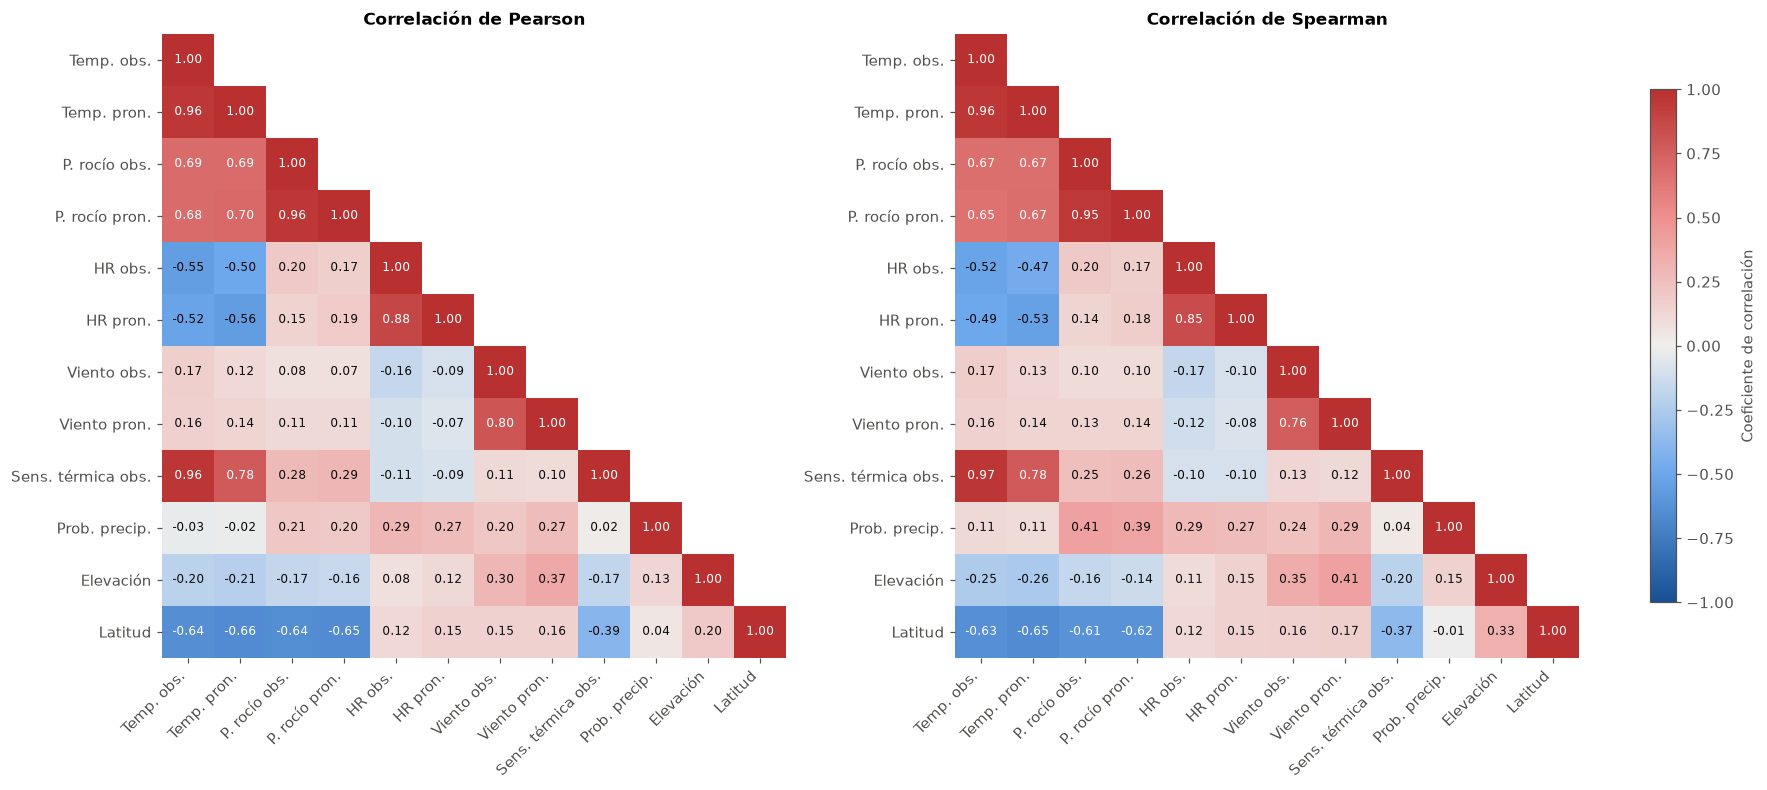

In [10]:
ETIQUETAS = {
    'obs_temp_c': 'Temp. obs.', 'fcst_temp_c': 'Temp. pron.',
    'obs_dewpoint_c': 'P. rocío obs.', 'fcst_dewpoint_c': 'P. rocío pron.',
    'obs_rh_pct': 'HR obs.', 'fcst_rh_pct': 'HR pron.',
    'obs_windspeed_kmh': 'Viento obs.', 'fcst_windspeed_kmh': 'Viento pron.',
    'obs_heat_index_c': 'Sens. térmica obs.', 'fcst_pop_pct': 'Prob. precip.',
    'elevation': 'Elevación', 'latitud': 'Latitud',
}
vars_corr = list(ETIQUETAS)
datos_corr = mp[vars_corr].rename(columns=ETIQUETAS)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, metodo, titulo in zip(axes, ['pearson', 'spearman'], ['Pearson', 'Spearman']):
    corr = datos_corr.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
    im = ax.imshow(corr.mask(mascara), cmap=DIVERGENTE, vmin=-1, vmax=1)
    for i in range(len(corr)):
        for j in range(i + 1):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(v) > 0.6 else '#0b0b0b')
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(corr)), corr.index)
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set_title(f'Correlación de {titulo}')
fig.colorbar(im, ax=axes, shrink=0.8, label='Coeficiente de correlación')
figuras['01_matriz_correlacion'] = fig
plt.show()

## 3. Observado vs. pronosticado

Cada panel compara la observación con el pronóstico emitido 6 h antes. Se usa un **hexbin** con la cantidad de
registros por celda en escala logarítmica. La línea punteada es `y = x` (pronóstico perfecto).

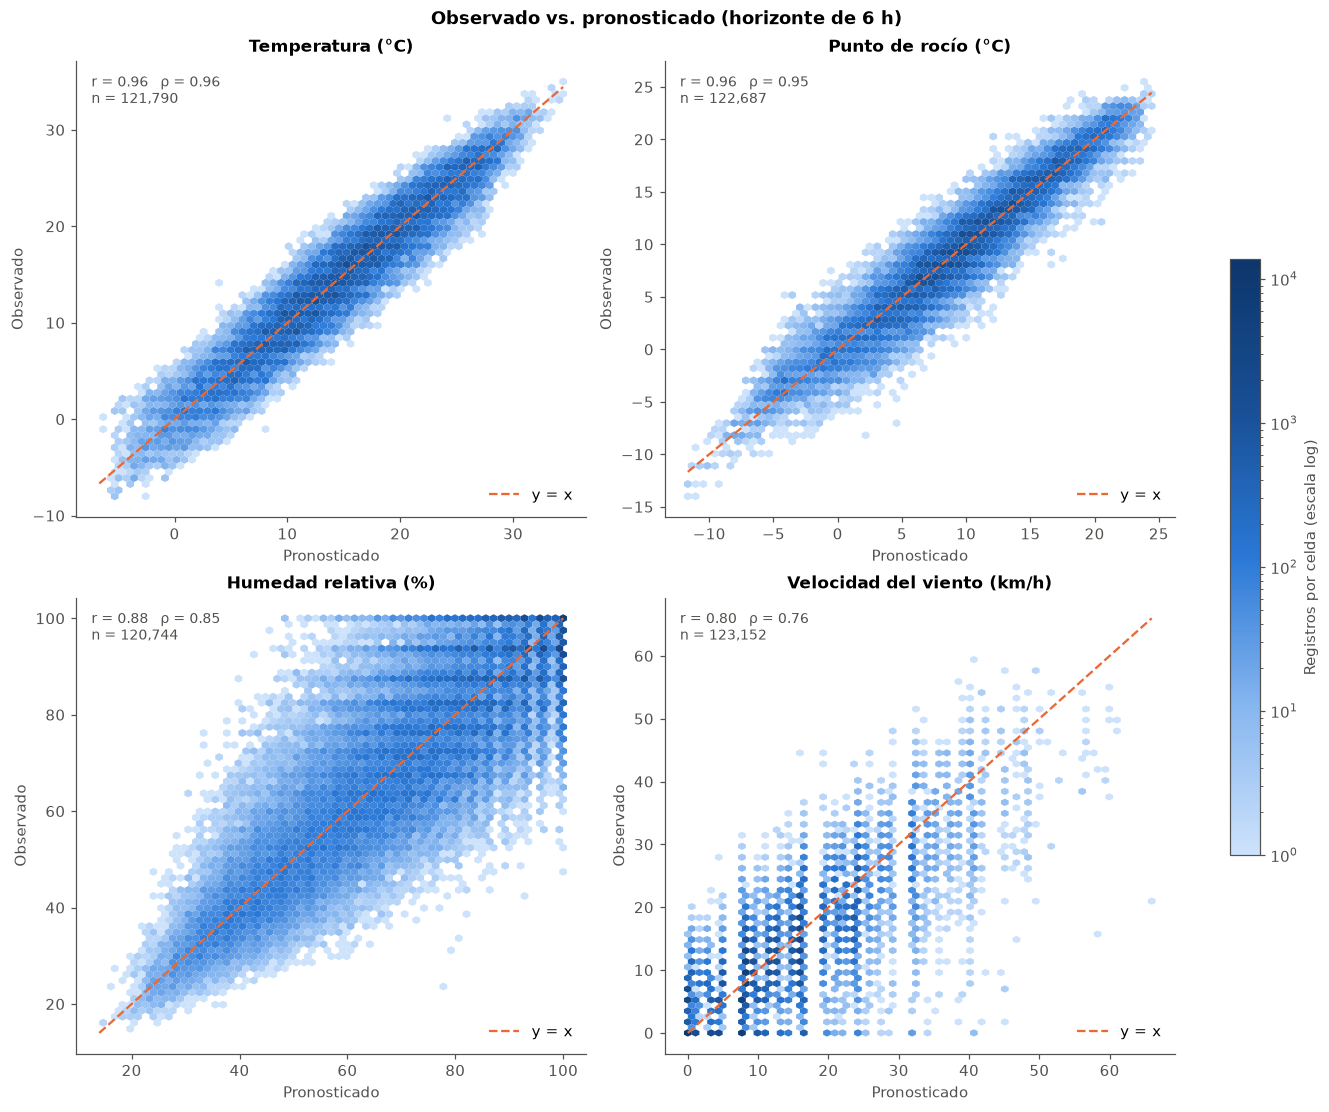

In [11]:
PARES_OBS_PRON = [
    ('Temperatura (°C)', 'fcst_temp_c', 'obs_temp_c'),
    ('Punto de rocío (°C)', 'fcst_dewpoint_c', 'obs_dewpoint_c'),
    ('Humedad relativa (%)', 'fcst_rh_pct', 'obs_rh_pct'),
    ('Velocidad del viento (km/h)', 'fcst_windspeed_kmh', 'obs_windspeed_kmh'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (nombre, pron, obs) in zip(axes.flat, PARES_OBS_PRON):
    hexbins.append(hexbin_par(ax, mp, pron, obs, identidad=True))
    ax.set(title=nombre, xlabel='Pronosticado', ylabel='Observado')
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Observado vs. pronosticado (horizonte de 6 h)', fontweight='bold')
figuras['02_observado_vs_pronosticado'] = fig
plt.show()

Resumen numérico del acuerdo entre observación y pronóstico (error = observado − pronosticado):

In [12]:
filas = []
for nombre, pron, obs in PARES_OBS_PRON:
    d = mp[[pron, obs]].dropna()
    error = d[obs] - d[pron]
    filas.append({
        'Variable': nombre, 'n': len(d),
        'Pearson r': d[obs].corr(d[pron]),
        'Sesgo (media del error)': error.mean(),
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt((error ** 2).mean()),
    })
tabla_obs_pron = pd.DataFrame(filas).set_index('Variable').round(2)
tabla_obs_pron

,n,Pearson r,Sesgo (media del error),MAE,RMSE
Variable,,,,,
Temperatura (°C),121790,0.96,-0.00,1.48,1.88
Punto de rocío (°C),122687,0.96,-0.04,1.20,1.58
Humedad relativa (%),120744,0.88,0.06,7.41,9.80
Velocidad del viento (km/h),123152,0.80,-0.70,3.74,5.16


### ¿Por qué el viento se ajusta mejor acá que en TP2?

En TP2 el viento era la variable peor ajustada por lejos (r = 0,52, frente a r ≥ 0,89 en el resto). Acá sigue siendo
la peor, pero la diferencia es mucho más chica (r = 0,80 vs. r ≥ 0,88). La explicación no es que el pronóstico de
viento haya mejorado, sino que **cambió la composición de la muestra**: TP2 estaba dominado por `CENTERPOINT`
(96.676 filas, el 52 % del total, r = 0,58) y por redes igual de ruidosas (`HADS`, `WEATHERSTEM`, `APRSWXNET`).
Esta muestra en cambio está dominada por `OTHER-MTR` y `ASOS-HFM` (el 73 % de las filas), ambas con r ≈ 0,81-0,82,
estaciones profesionales con el sensor a la altura estándar.

Lo que **no** cambió es la red de aficionados `APRSWXNET` (CWOP): sigue siendo la peor con claridad (r = 0,43, MAE
7,81, 47 % de calmas observadas cuando el pronóstico no indica calma) -prácticamente los mismos números que en TP2
(r = 0,35, MAE 7,77, 47 % de calmas). Mismo problema de fondo que en TP2: sensores caseros, mal ubicados y sin
calibrar, frente a un pronóstico que asume viento a 10 m en terreno abierto. La cuantización del pronóstico (pocos
valores posibles, casi siempre pasos de 1 mph) y que la observación sea puntual contra un pronóstico que representa
una celda de ≈ 2,5 km siguen afectando a todas las redes por igual.

La tabla compara las redes con más de 3.000 pares.

In [13]:
viento_red = mp[['red', 'fcst_windspeed_kmh', 'obs_windspeed_kmh']].dropna(subset=['fcst_windspeed_kmh', 'obs_windspeed_kmh'])


def metricas_viento(d):
    error = d['obs_windspeed_kmh'] - d['fcst_windspeed_kmh']
    return pd.Series({
        'n': len(d),
        'Pearson r': d['obs_windspeed_kmh'].corr(d['fcst_windspeed_kmh']),
        'Sesgo (media del error)': error.mean(),
        'MAE': error.abs().mean(),
        '% calmas obs.': 100 * d['obs_windspeed_kmh'].eq(0).mean(),
    })


import warnings

with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)  # redes con muy pocos pares dan corr NaN; se filtran después
    tabla_viento_red = (viento_red.groupby('red')[['fcst_windspeed_kmh', 'obs_windspeed_kmh']].apply(metricas_viento)
                        .query('n > 3000').sort_values('Pearson r', ascending=False))
tabla_viento_red.loc['Todas'] = metricas_viento(viento_red)
tabla_viento_red.loc['Todas sin APRSWXNET'] = metricas_viento(viento_red[viento_red['red'] != 'APRSWXNET'])
tabla_viento_red['n'] = tabla_viento_red['n'].astype(int)
tabla_viento_red.round(2)

,n,Pearson r,Sesgo (media del error),MAE,% calmas obs.
red,,,,,
OTHER-MTR,47917,0.82,-0.27,3.47,25.35
TG,9462,0.82,-0.17,3.56,27.44
ASOS-HFM,42065,0.81,-0.65,3.71,19.30
RAWS,10145,0.80,-1.45,3.70,16.46
ASOS,3519,0.80,-0.82,3.93,17.19
APRSWXNET,3102,0.43,-7.02,7.81,47.23
Todas,123152,0.80,-0.70,3.74,22.39
Todas sin APRSWXNET,120050,0.81,-0.54,3.64,21.75


## 4. Relaciones entre variables observadas

Relaciones físicas esperables entre las mediciones:

- **Temperatura vs. humedad relativa**: con la misma cantidad de vapor, el aire más caliente tiene menor HR.
- **Temperatura vs. punto de rocío**: el punto de rocío nunca supera a la temperatura (cota superior `y = x`).
- **Temperatura vs. sensación térmica**: coinciden con calor seco y se separan cuando la humedad es alta.
- **Humedad relativa vs. viento**: el viento mezcla el aire y suele coincidir con horas de menor HR.

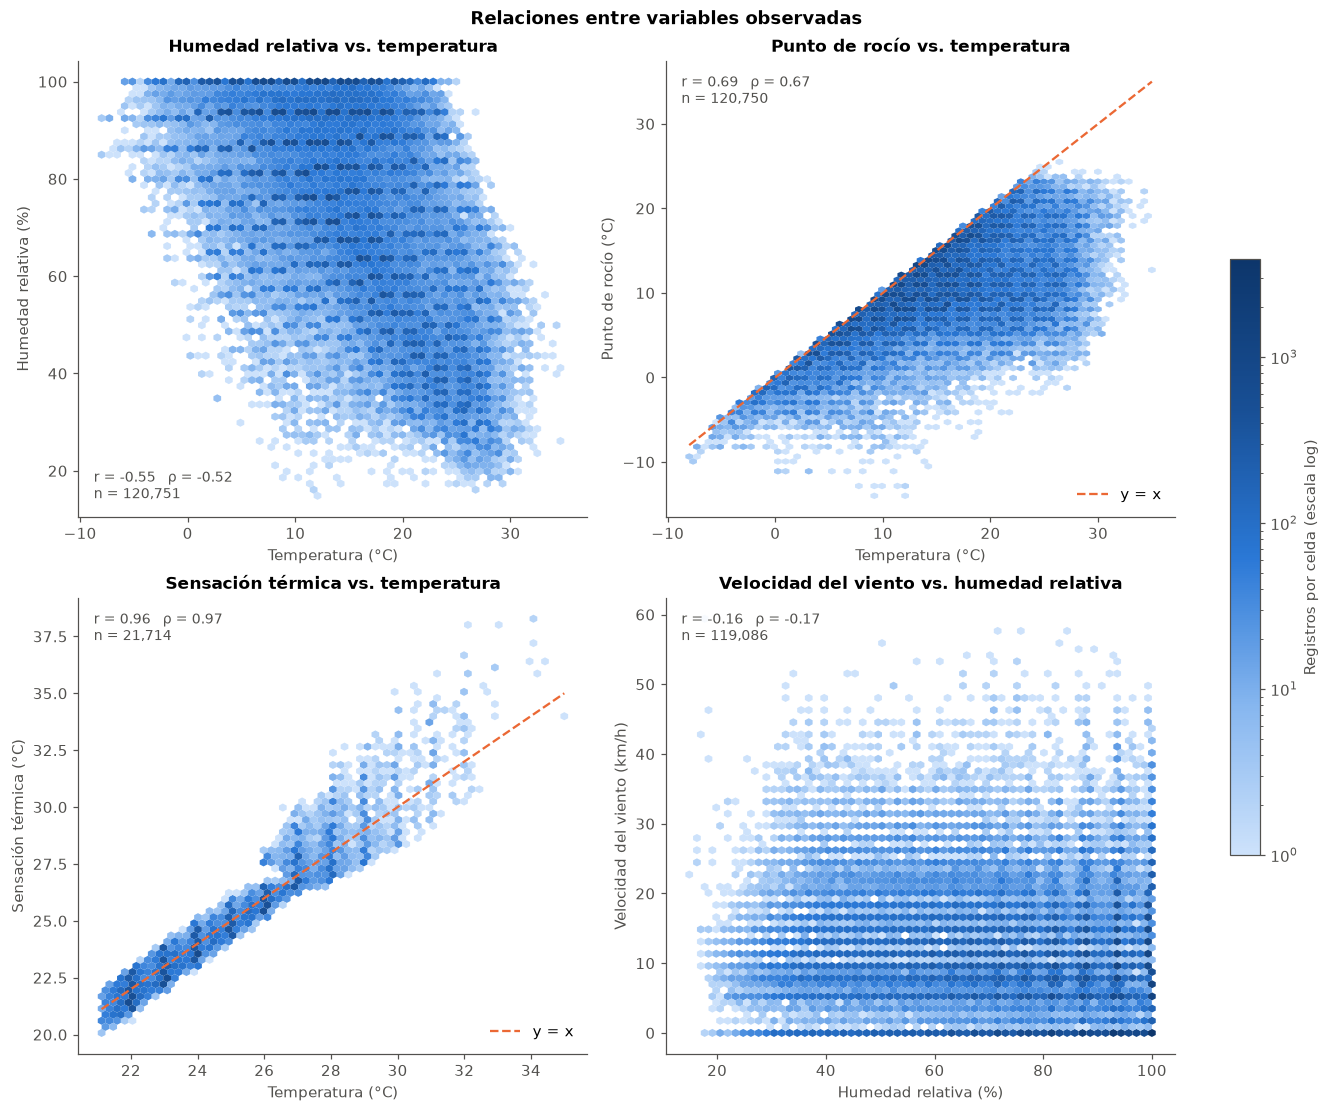

In [14]:
PARES_OBS = [
    ('obs_temp_c', 'obs_rh_pct', 'Temperatura (°C)', 'Humedad relativa (%)', False, True),
    ('obs_temp_c', 'obs_dewpoint_c', 'Temperatura (°C)', 'Punto de rocío (°C)', True, False),
    ('obs_temp_c', 'obs_heat_index_c', 'Temperatura (°C)', 'Sensación térmica (°C)', True, False),
    ('obs_rh_pct', 'obs_windspeed_kmh', 'Humedad relativa (%)', 'Velocidad del viento (km/h)', False, False),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (x, y, etiqueta_x, etiqueta_y, identidad, texto_abajo) in zip(axes.flat, PARES_OBS):
    hexbins.append(hexbin_par(ax, mp, x, y, identidad=identidad, texto_abajo=texto_abajo))
    ax.set(title=f'{etiqueta_y.split(" (")[0]} vs. {etiqueta_x.split(" (")[0].lower()}',
           xlabel=etiqueta_x, ylabel=etiqueta_y)
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Relaciones entre variables observadas', fontweight='bold')
figuras['03_relaciones_observadas'] = fig
plt.show()

## 5. Ciclo diario

Cada variable se grafica contra la hora local. La línea es la media y la banda el rango intercuartílico (P25–P75)
de todas las estaciones y días. Se usa la media y no la mediana porque el pronóstico de viento toma pocos valores
(8,05 km/h = 5 mph, 16,09 km/h = 10 mph, ...) y su mediana salta de un escalón a otro -el mismo esquema de
cuantización que en TP2. Se usa un panel por variable para no mezclar escalas en un mismo eje.

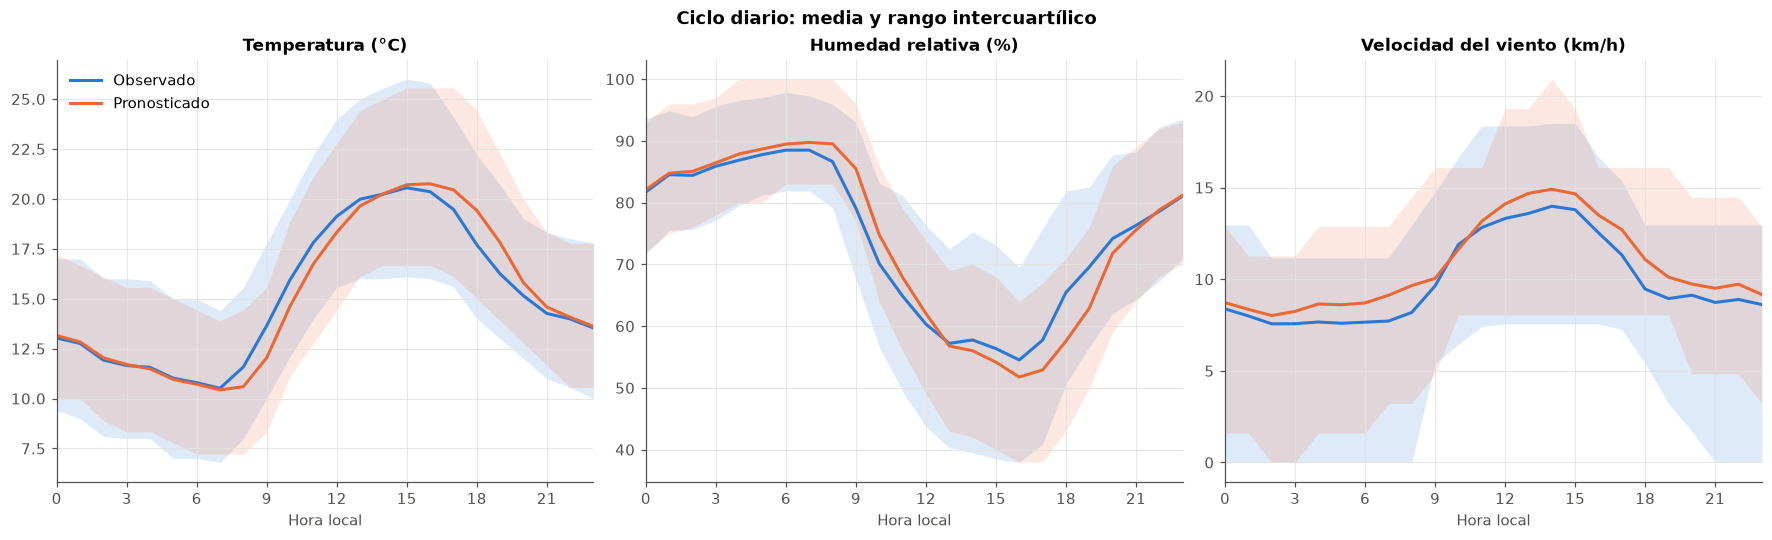

In [15]:
CICLO = [
    ('Temperatura (°C)', 'obs_temp_c', 'fcst_temp_c'),
    ('Humedad relativa (%)', 'obs_rh_pct', 'fcst_rh_pct'),
    ('Velocidad del viento (km/h)', 'obs_windspeed_kmh', 'fcst_windspeed_kmh'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, (nombre, obs, pron) in zip(axes, CICLO):
    banda_por_hora(ax, mp, obs, AZUL, 'Observado')
    banda_por_hora(ax, mp, pron, NARANJA, 'Pronosticado')
    ax.set(title=nombre, xlabel='Hora local', xticks=range(0, 24, 3), xlim=(0, 23))
axes[0].legend(frameon=False)
fig.suptitle('Ciclo diario: media y rango intercuartílico', fontweight='bold')
figuras['04_ciclo_diario'] = fig
plt.show()

## 6. Error del pronóstico de temperatura

Se analiza el error `observado − pronosticado` de la temperatura frente a dos variables:

- la **hora local**, para ver si el modelo falla sistemáticamente en algún momento del día;
- la **probabilidad de precipitación** pronosticada, ya que la lluvia y la nubosidad son difíciles de anticipar
  y enfrían el aire.

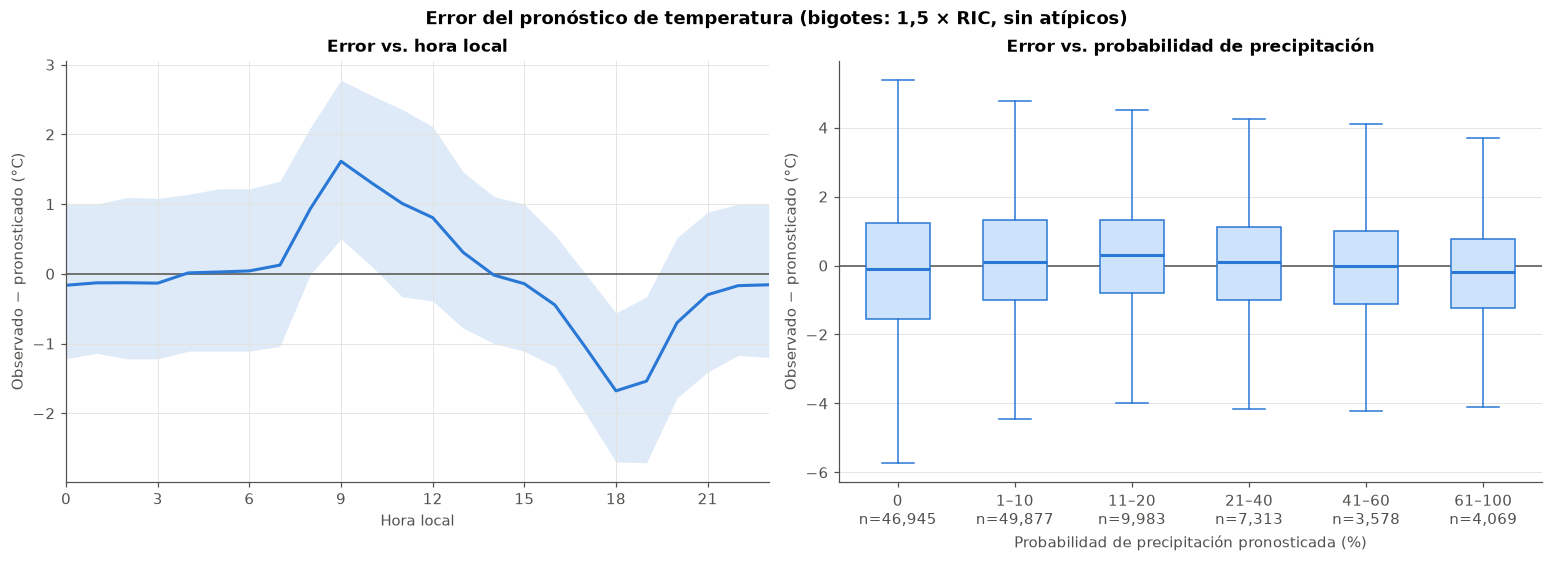

In [16]:
mp['error_temp_c'] = mp['obs_temp_c'] - mp['fcst_temp_c']

cortes_pop = [-0.1, 0, 10, 20, 40, 60, 100]
etiquetas_pop = ['0', '1–10', '11–20', '21–40', '41–60', '61–100']
mp['pop_rango'] = pd.cut(mp['fcst_pop_pct'], cortes_pop, labels=etiquetas_pop)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax1.axhline(0, color=GRIS_TEXTO, lw=1)
banda_por_hora(ax1, mp, 'error_temp_c', AZUL, 'Media')
ax1.set(title='Error vs. hora local', xlabel='Hora local', ylabel='Observado − pronosticado (°C)',
        xticks=range(0, 24, 3), xlim=(0, 23))

d = mp.dropna(subset=['error_temp_c'])
grupos = [g['error_temp_c'].values for _, g in d.groupby('pop_rango', observed=False)]
ax2.axhline(0, color=GRIS_TEXTO, lw=1)
etiquetas_n = [f'{e}\nn={len(g):,}' for e, g in zip(etiquetas_pop, grupos)]
ax2.boxplot(grupos, tick_labels=etiquetas_n, showfliers=False, widths=0.55, patch_artist=True,
            boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
            whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax2.set(title='Error vs. probabilidad de precipitación', xlabel='Probabilidad de precipitación pronosticada (%)',
        ylabel='Observado − pronosticado (°C)')
ax2.grid(axis='x', visible=False)

fig.suptitle('Error del pronóstico de temperatura (bigotes: 1,5 × RIC, sin atípicos)', fontweight='bold')
figuras['05_error_temperatura'] = fig
plt.show()

In [17]:
(mp.groupby('pop_rango', observed=False)['error_temp_c']
 .agg(n='count', sesgo='mean', mediana='median', MAE=lambda e: e.abs().mean())
 .round(2))

,n,sesgo,mediana,MAE
pop_rango,,,,
0,46945,-0.15,-0.11,1.65
1–10,49877,0.13,0.11,1.41
11–20,9983,0.20,0.31,1.35
21–40,7313,-0.03,0.10,1.33
41–60,3578,-0.12,0.00,1.32
61–100,4069,-0.27,-0.19,1.24


## 7. Dirección vs. velocidad del viento

Rosa de los vientos: cada barra es un sector de 22,5° según la dirección **desde la que sopla** el viento (0° = norte),
su largo es el porcentaje de observaciones en ese sector y los tramos apilados indican la velocidad (más oscuro = más rápido).
Se excluyen las calmas (velocidad 0), que se reportan con dirección 0°.

Calmas excluidas: 27,570 (22.6% de las observaciones de viento)


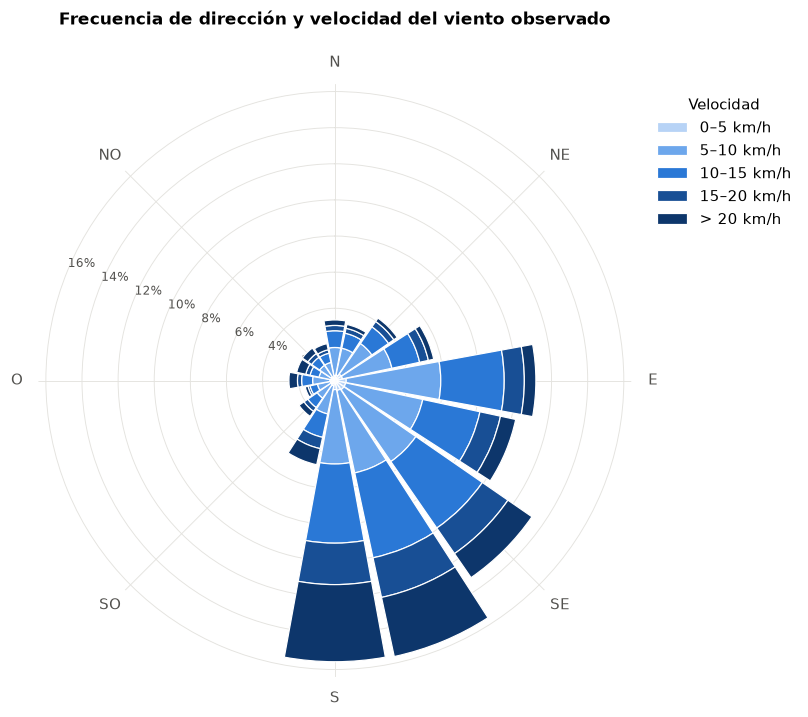

In [18]:
viento = mp[['obs_wind_direction_d', 'obs_windspeed_kmh']].dropna()
calmas = viento['obs_windspeed_kmh'].eq(0)
print(f'Calmas excluidas: {calmas.sum():,} ({calmas.mean():.1%} de las observaciones de viento)')
viento = viento[~calmas]

SECTOR = 22.5
cortes_vel = [0, 5, 10, 15, 20, np.inf]
etiquetas_vel = ['0–5', '5–10', '10–15', '15–20', '> 20']
colores_vel = ['#b7d3f6', '#6da7ec', '#2a78d6', '#184f95', '#0d366b']

sector = ((viento['obs_wind_direction_d'] + SECTOR / 2) % 360 // SECTOR).astype(int)
rango_vel = pd.cut(viento['obs_windspeed_kmh'], cortes_vel, labels=etiquetas_vel)
frecuencia = (pd.crosstab(sector, rango_vel, normalize=True) * 100).reindex(range(16), fill_value=0)

angulos = np.deg2rad(frecuencia.index * SECTOR)
fig = plt.figure(figsize=(7.5, 7))
ax = fig.add_subplot(projection='polar')
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
base = np.zeros(len(frecuencia))
for etiqueta, color in zip(etiquetas_vel, colores_vel):
    ax.bar(angulos, frecuencia[etiqueta], width=np.deg2rad(SECTOR) * 0.92, bottom=base,
           color=color, edgecolor='white', linewidth=0.8, label=f'{etiqueta} km/h')
    base += frecuencia[etiqueta].values
ax.set_xticks(np.deg2rad(range(0, 360, 45)), ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO'])
ax.set_rlabel_position(292.5)  # sector con poco viento, las etiquetas no quedan tapadas
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.tick_params(axis='y', labelsize=8, colors=GRIS_TEXTO)
ax.grid(color=GRIS_GRILLA)
ax.set_axisbelow(True)
ax.spines['polar'].set_visible(False)
ax.legend(title='Velocidad', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title('Frecuencia de dirección y velocidad del viento observado', pad=20)
figuras['06_direccion_velocidad_viento'] = fig
plt.show()

In [19]:
sectores = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
viento['sector'] = pd.Categorical(
    np.array(sectores)[(((viento['obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)], sectores)
(viento.groupby('sector', observed=False)['obs_windspeed_kmh']
 .agg(frecuencia_pct=lambda s: 100 * len(s) / len(viento), mediana_kmh='median', p90_kmh=lambda s: s.quantile(0.9))
 .round(1))

,frecuencia_pct,mediana_kmh,p90_kmh
sector,,,
N,5.9,9.4,19.3
NE,8.5,9.3,16.7
E,19.0,9.4,18.4
SE,26.6,11.2,20.5
S,26.0,13.0,25.9
SO,5.2,11.1,22.2
O,4.5,11.1,25.9
NO,4.3,11.1,24.1


### Distribución geográfica del viento

A diferencia de TP2 -donde el 70 % de las observaciones venía de la franja del Golfo porque la muestra estaba
muy concentrada en el área de Houston (CENTERPOINT)-, acá las 500 estaciones se reparten de forma mucho más
pareja por los 15 estados de la región central: sólo el 12 % de las observaciones de viento viene de la franja
del Golfo (25–31°) y Texas aporta el 22 % (vs. 64 % en TP2). No hay un cluster geográfico que justifique un
recuadro ampliado como el de Houston en TP2, así que se grafica directamente el mapa completo.

Para ver cómo cambia el viento en el territorio y cómo se relaciona con el error del pronóstico, se dibuja una
flecha por estación (las que tienen al menos 100 observaciones de viento):

- **Dirección**: promedio vectorial de las observaciones sin calmas. La flecha apunta **hacia donde va** el viento (la rosa usa la
  dirección desde la que sopla), así que un viento del SE se ve como una flecha hacia el NO.
- **Largo**: constancia = |vector medio| / velocidad media. Vale 1 si el viento sopla siempre del mismo lado y se acerca a 0 cuando
  llega de cualquier dirección.
- **Color**: sesgo de la velocidad (observado − pronosticado). En rojo, las estaciones donde el pronóstico sobreestima el viento.

In [20]:
con_dir = mp[mp['obs_windspeed_kmh'].gt(0)].dropna(subset=['obs_wind_direction_d'])
rad = np.deg2rad(con_dir['obs_wind_direction_d'])
con_dir = con_dir.assign(u=con_dir['obs_windspeed_kmh'] * np.sin(rad), v=con_dir['obs_windspeed_kmh'] * np.cos(rad))


def vector_medio(d):
    """Dirección resultante (desde donde sopla, en grados) y constancia de un conjunto de observaciones."""
    u, v = d['u'].mean(), d['v'].mean()
    return pd.Series({
        'n': len(d),
        'direccion': np.rad2deg(np.arctan2(u, v)) % 360,
        'constancia': np.hypot(u, v) / d['obs_windspeed_kmh'].mean(),
        'vel_media_kmh': d['obs_windspeed_kmh'].mean(),
    })


pares_viento = mp.dropna(subset=['obs_windspeed_kmh', 'fcst_windspeed_kmh'])
pares_viento = pares_viento.assign(error=pares_viento['obs_windspeed_kmh'] - pares_viento['fcst_windspeed_kmh'])
coords = estaciones.set_index('station_id')[['latitud', 'longitud']]

viento_estacion = (con_dir.groupby('station_id')[['u', 'v', 'obs_windspeed_kmh']].apply(vector_medio)
                   .query('n >= 100')
                   .join(pares_viento.groupby('station_id')['error'].mean().rename('sesgo_kmh'))
                   .join(coords))
print(f'Estaciones en el mapa: {len(viento_estacion)}')
viento_estacion[['direccion', 'constancia', 'vel_media_kmh', 'sesgo_kmh']].describe().round(2)

Estaciones en el mapa: 443


,direccion,constancia,vel_media_kmh,sesgo_kmh
count,443.00,443.00,443.00,443.00
mean,143.98,0.59,12.25,-0.61
std,40.33,0.22,3.61,1.83
min,14.87,0.02,2.99,-15.28
25%,121.53,0.42,9.79,-1.29
50%,143.08,0.63,11.98,-0.40
75%,162.26,0.78,15.11,0.34
max,327.08,0.94,22.21,5.12


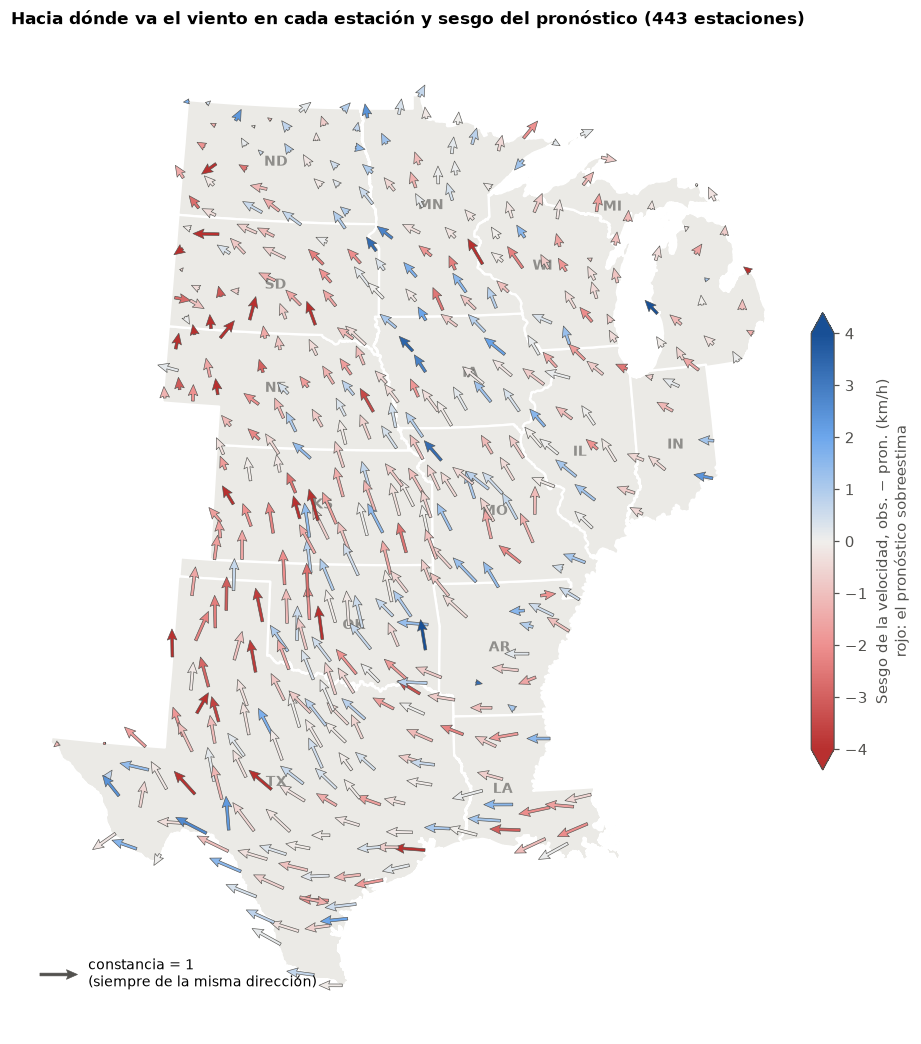

In [21]:
from matplotlib.colors import CenteredNorm

CRS_METRICO = 'EPSG:5070'  # el mismo de analisis_estaciones.ipynb
estados_mapa = gpd.read_file(PROCESSED + 'estados_central.geojson').to_crs(CRS_METRICO)

# Punta de cada flecha: se desplaza el punto hacia donde va el viento en lon/lat y se proyecta,
# así la dirección respeta el norte verdadero aunque la proyección rote los meridianos
lat, lon = viento_estacion['latitud'].values, viento_estacion['longitud'].values
hacia = np.deg2rad(viento_estacion['direccion'].values + 180)
origen = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs='EPSG:4326').to_crs(CRS_METRICO)
punta = gpd.GeoSeries(gpd.points_from_xy(lon + 0.1 * np.sin(hacia) / np.cos(np.deg2rad(lat)),
                                         lat + 0.1 * np.cos(hacia)), crs='EPSG:4326').to_crs(CRS_METRICO)
dx, dy = punta.x.values - origen.x.values, punta.y.values - origen.y.values
largo = viento_estacion['constancia'].values / np.hypot(dx, dy)
U, V = dx * largo, dy * largo

norma = CenteredNorm(vcenter=0, halfrange=np.ceil(viento_estacion['sesgo_kmh'].abs().quantile(0.95)))
cmap_sesgo = DIVERGENTE.reversed()  # rojo = el pronóstico sobreestima (sesgo negativo)

fig, ax = plt.subplots(figsize=(11, 12))
estados_mapa.plot(ax=ax, color='#ebeae6', edgecolor='white', linewidth=1.5)
for _, fila in estados_mapa.iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(fila['estado'], (p.x, p.y), ha='center', va='center', fontsize=9, color=GRIS_TEXTO,
                fontweight='bold', alpha=0.6, zorder=2)
q = ax.quiver(origen.x, origen.y, U, V, viento_estacion['sesgo_kmh'], scale=1 / (110 * 1000),
             width=0.0035, headwidth=3.5, headlength=4, headaxislength=3.5,
             cmap=cmap_sesgo, norm=norma, angles='xy', scale_units='xy', pivot='tail',
             edgecolor=GRIS_TEXTO, linewidth=0.4, zorder=3)
ax.quiverkey(q, 0.08, 0.06, 1, 'constancia = 1\n(siempre de la misma dirección)', labelpos='E',
             coordinates='axes', color=GRIS_TEXTO, fontproperties={'size': 9})

fig.colorbar(q, ax=ax, shrink=0.45, pad=0.01, extend='both',
             label='Sesgo de la velocidad, obs. − pron. (km/h)\nrojo: el pronóstico sobreestima')
ax.set_title(f'Hacia dónde va el viento en cada estación y sesgo del pronóstico ({len(viento_estacion)} estaciones)')
ax.set_axis_off()
figuras['07_mapa_viento'] = fig
plt.show()

Resumen por franja de latitud. Se repite sin APRSWXNET para separar el efecto de la ubicación del de la red (la red de aficionados subestima mucho el viento, igual que en TP2).

In [22]:
FRANJAS = [25, 31, 37, 43, 50]
ETIQUETAS_FRANJA = ['25–31° (Golfo)', '31–37°', '37–43°', '43–50° (norte)']

for d in (con_dir, pares_viento):
    d['franja'] = pd.cut(d['station_id'].map(coords['latitud']), FRANJAS, labels=ETIQUETAS_FRANJA)


def resumen_franjas(dir_, pares):
    """Vector medio, sesgo de la velocidad y % de observaciones por sector, por franja de latitud."""
    tabla = dir_.groupby('franja', observed=True)[['u', 'v', 'obs_windspeed_kmh']].apply(vector_medio)
    tabla['% obs.'] = 100 * tabla['n'] / tabla['n'].sum()
    tabla['sesgo_kmh'] = pares.groupby('franja', observed=True)['error'].mean()
    sector = np.array(sectores)[(((dir_['obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)]
    return tabla.join(pd.crosstab(dir_['franja'], sector, normalize='index').mul(100)[sectores])


tabla_viento_franja = pd.concat({
    'Todas las redes': resumen_franjas(con_dir, pares_viento),
    'Sin APRSWXNET': resumen_franjas(con_dir[con_dir['red'] != 'APRSWXNET'], pares_viento[pares_viento['red'] != 'APRSWXNET']),
})
tabla_viento_franja['n'] = tabla_viento_franja['n'].astype(int)
tabla_viento_franja = tabla_viento_franja.round({'direccion': 0, 'constancia': 2, 'vel_media_kmh': 1, '% obs.': 1,
                                                 'sesgo_kmh': 2, **{s: 0 for s in sectores}})
tabla_viento_franja

n  direccion  constancia  vel_media_kmh  \
                franja                                                        
Todas las redes 25–31° (Golfo)  11745      104.0        0.67           11.8   
                31–37°          22014      152.0        0.70           11.7   
                37–43°          30733      150.0        0.58           12.6   
                43–50° (norte)  29824      147.0        0.32           13.7   
Sin APRSWXNET   25–31° (Golfo)  11574      105.0        0.67           11.8   
                31–37°          21503      152.0        0.71           11.8   
                37–43°          29964      150.0        0.58           12.7   
                43–50° (norte)  29637      147.0        0.32           13.8   

                                % obs.  sesgo_kmh    N    NE     E    SE  \
                franja                                                     
Todas las redes 25–31° (Golfo)    12.5      -0.52  8.0  17.0  35.0  26.0   
                31–37°            23.3      -0.52  3.0   7.0  18.0  30.0   
                37–43°            32.6      -1.03  5.0   7.0  16.0  27.0   
                43–50° (norte)    31.6      -0.57  8.0   8.0  16.0  24.0   
Sin APRSWXNET   25–31° (Golfo)    12.5      -0.50  8.0  17.0  35.0  26.0   
                31–37°            23.2      -0.43  4.0   7.0  18.0  30.0   
                37–43°            32.3      -0.71  5.0   7.0  16.0  27.0   
                43–50° (norte)    32.0      -0.47  8.0   7.0  16.0  25.0   

                                   S   SO    O   NO  
                franja                               
Todas las redes 25–31° (Golfo)   9.0  2.0  2.0  2.0  
                31–37°          32.0  5.0  2.0  2.0  
                37–43°          33.0  6.0  3.0  3.0  
                43–50° (norte)  21.0  6.0  9.0  8.0  
Sin APRSWXNET   25–31° (Golfo)   9.0  2.0  2.0  2.0  
                31–37°          33.0  5.0  2.0  2.0  
                37–43°          33.0  6.0  3.0  3.0  
                43–50° (norte)  21.0  6.0  9.0  9.0

## 8. Error del pronóstico por variable

En esta sección el error se define como **pronosticado − observado** (signo opuesto al de las secciones anteriores):
un error positivo indica que el pronóstico **sobreestima** la variable y uno negativo que la subestima.
Para cada variable se usan todos los pares completos y se informan:

- **Sesgo**: media del error (error sistemático).
- **MAE**: media del error absoluto (tamaño típico del error, en las unidades de la variable).
- **RMSE**: raíz del error cuadrático medio. Penaliza más los errores grandes, así que RMSE ≫ MAE indica colas pesadas.
- **n**: cantidad de pares observación–pronóstico.

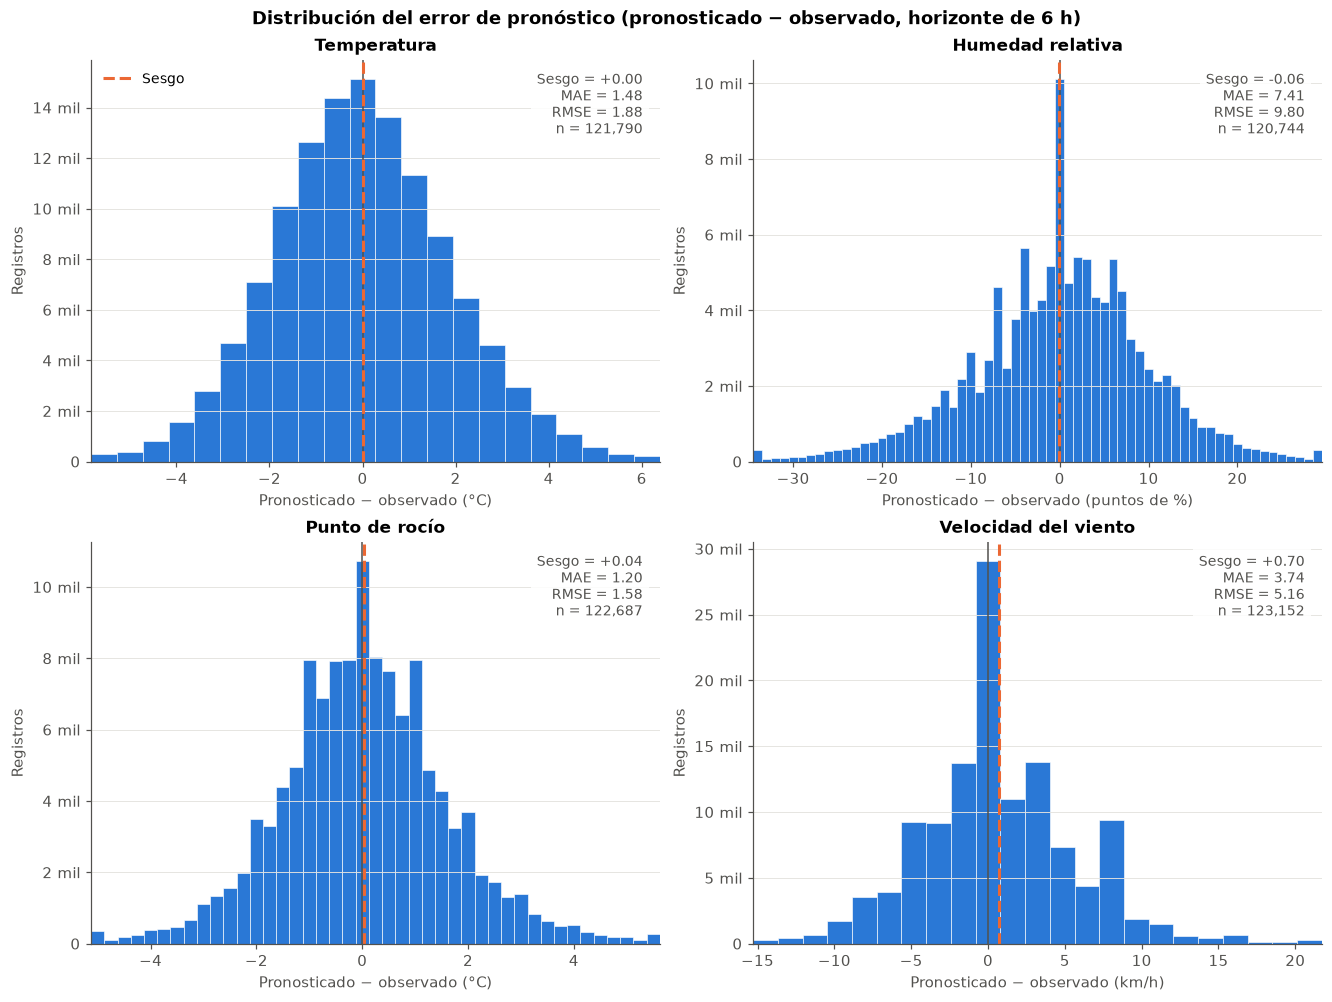

,n,Sesgo,MAE,RMSE
Temperatura,121790,0.00,1.48,1.88
Humedad relativa,120744,-0.06,7.41,9.80
Punto de rocío,122687,0.04,1.20,1.58
Velocidad del viento,123152,0.70,3.74,5.16


In [23]:
# Ancho de clase del histograma: en temperatura y viento coincide con el paso del pronóstico (1 °F y 1 mph),
# porque los errores se agrupan en sus múltiplos y otro ancho genera picos falsos
ERRORES = [
    ('Temperatura', '°C', 'fcst_temp_c', 'obs_temp_c', 5 / 9),
    ('Humedad relativa', 'puntos de %', 'fcst_rh_pct', 'obs_rh_pct', 1),
    ('Punto de rocío', '°C', 'fcst_dewpoint_c', 'obs_dewpoint_c', 0.25),
    ('Velocidad del viento', 'km/h', 'fcst_windspeed_kmh', 'obs_windspeed_kmh', 1.609344),
]
for nombre, _, pron, obs, _ in ERRORES:
    mp[f'error_{nombre}'] = mp[pron] - mp[obs]  # pronosticado − observado


def metricas_error(e):
    e = e.dropna()
    return pd.Series({'n': len(e), 'Sesgo': e.mean(), 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean())})


fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
filas = {}
for ax, (nombre, unidad, _, _, paso) in zip(axes.flat, ERRORES):
    e = mp[f'error_{nombre}'].dropna()
    m = filas[nombre] = metricas_error(e)
    # El eje cubre el 99,5 % central para que las colas no aplasten el histograma (las métricas usan todos los datos).
    # Las clases se centran en múltiplos del paso, así el error nulo cae en el medio de una barra
    k_min, k_max = np.floor(e.quantile(0.0025) / paso), np.ceil(e.quantile(0.9975) / paso)
    bins = (np.arange(k_min, k_max + 2) - 0.5) * paso
    ax.hist(e.clip(bins[0], bins[-1]), bins=bins, color=AZUL, edgecolor='white', linewidth=0.4)
    ax.axvline(0, color=GRIS_TEXTO, lw=1)
    ax.axvline(m['Sesgo'], color=NARANJA, lw=2, ls='--', label='Sesgo')
    ax.text(0.97, 0.97, f'Sesgo = {m["Sesgo"]:+.2f}\nMAE = {m["MAE"]:.2f}\nRMSE = {m["RMSE"]:.2f}\nn = {m["n"]:,.0f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
    ax.set(title=nombre, xlabel=f'Pronosticado − observado ({unidad})', ylabel='Registros', xlim=(bins[0], bins[-1]))
    ax.yaxis.set_major_formatter(lambda v, _: f'{v / 1000:g} mil'.replace('.', ',') if v else '0')
    ax.grid(axis='x', visible=False)
axes[0, 0].legend(loc='upper left', frameon=False, fontsize=9)
fig.suptitle('Distribución del error de pronóstico (pronosticado − observado, horizonte de 6 h)', fontweight='bold')
figuras['08_distribucion_error'] = fig
plt.show()

tabla_error = pd.DataFrame(filas).T
tabla_error['n'] = tabla_error['n'].astype(int)
tabla_error.round(2)

Los histogramas muestran el 99,5 % central de cada distribución (los valores más extremos se acumulan en las barras de los bordes);
las métricas se calculan con todos los pares. La línea gris marca el error nulo y la naranja el sesgo.
El pronóstico de temperatura viene en °F enteros y el de viento en mph enteras, así que sus errores se agrupan en múltiplos
de 5/9 °C y de 1,609 km/h: el ancho de las barras coincide con ese paso para no generar picos artificiales.

### Variación del error según la hora del día

Para cada variable y hora local se grafica el **sesgo** (media del error, con el rango intercuartílico P25–P75 como banda)
y el **MAE**. El sesgo indica en qué horas el pronóstico se corre sistemáticamente hacia arriba o hacia abajo; el MAE, en qué
horas falla más, sin importar el signo.

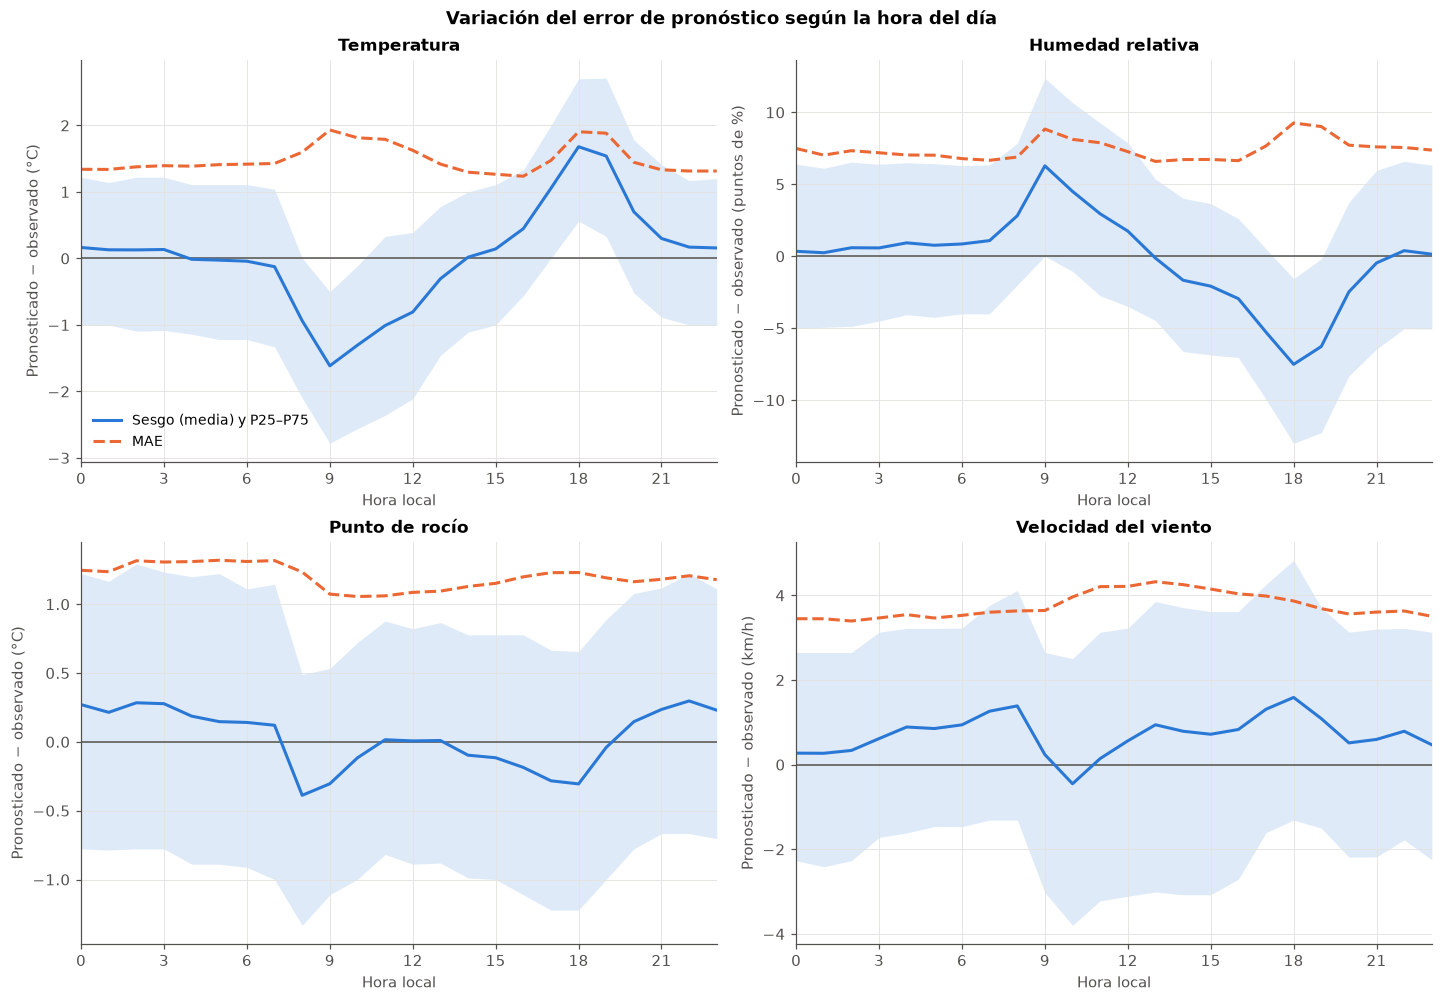

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, (nombre, unidad, *_) in zip(axes.flat, ERRORES):
    col = f'error_{nombre}'
    ax.axhline(0, color=GRIS_TEXTO, lw=1)
    banda_por_hora(ax, mp, col, AZUL, 'Sesgo (media) y P25–P75')
    mae_hora = mp[col].abs().groupby(mp['hora_local']).mean()
    ax.plot(mae_hora.index, mae_hora.values, color=NARANJA, lw=2, ls='--', label='MAE')
    ax.set(title=nombre, xlabel='Hora local', ylabel=f'Pronosticado − observado ({unidad})',
           xticks=range(0, 24, 3), xlim=(0, 23))
axes[0, 0].legend(frameon=False, loc='lower left', fontsize=9)
fig.suptitle('Variación del error de pronóstico según la hora del día', fontweight='bold')
figuras['09_error_por_hora'] = fig
plt.show()

Horas en que el sesgo y el MAE alcanzan sus extremos, para cada variable:

In [25]:
filas = {}
for nombre, *_ in ERRORES:
    g = mp.groupby('hora_local')[f'error_{nombre}']
    sesgo, mae = g.mean(), g.apply(lambda e: e.abs().mean())
    filas[nombre] = {
        'Sesgo mín.': sesgo.min(), 'hora sesgo mín.': sesgo.idxmin(),
        'Sesgo máx.': sesgo.max(), 'hora sesgo máx.': sesgo.idxmax(),
        'MAE mín.': mae.min(), 'hora MAE mín.': mae.idxmin(),
        'MAE máx.': mae.max(), 'hora MAE máx.': mae.idxmax(),
    }
tabla_error_hora = pd.DataFrame(filas).T
horas = [c for c in tabla_error_hora if c.startswith('hora')]
tabla_error_hora[horas] = tabla_error_hora[horas].astype(int)
tabla_error_hora.round(2)

,Sesgo mín.,hora sesgo mín.,Sesgo máx.,hora sesgo máx.,MAE mín.,hora MAE mín.,MAE máx.,hora MAE máx.
Temperatura,-1.61,9,1.68,18,1.24,16,1.93,9
Humedad relativa,-7.51,18,6.28,9,6.59,13,9.26,18
Punto de rocío,-0.39,8,0.30,22,1.06,10,1.32,5
Velocidad del viento,-0.45,10,1.59,18,3.39,2,4.32,13


### Sesgo según el valor observado

Se agrupan los pares por el valor **observado** de cada variable y en cada clase se calcula el sesgo (media de pronosticado − observado)
y el rango intercuartílico del error. Debajo de cada panel se muestra cuántos pares hay en cada clase. Sólo se grafican las clases con
al menos 200 pares. Las clases tienen el ancho de 1 °F en temperatura y punto de rocío, de 2 puntos en HR y de 1 mph en viento,
para respetar la resolución con la que se reportan los datos.

Al condicionar por la observación, cualquier pronóstico imperfecto muestra una pendiente negativa (regresión a la media): si se elige
un momento en que hizo mucho calor, lo más probable es que el pronóstico se haya quedado corto, aunque en promedio no tenga sesgo.
Por eso la pendiente indica que el pronóstico **no alcanza los extremos** observados, y lo que distingue a cada variable es cuán
pronunciada es y si la curva cruza el cero en el centro de la distribución o desplazada hacia un lado.

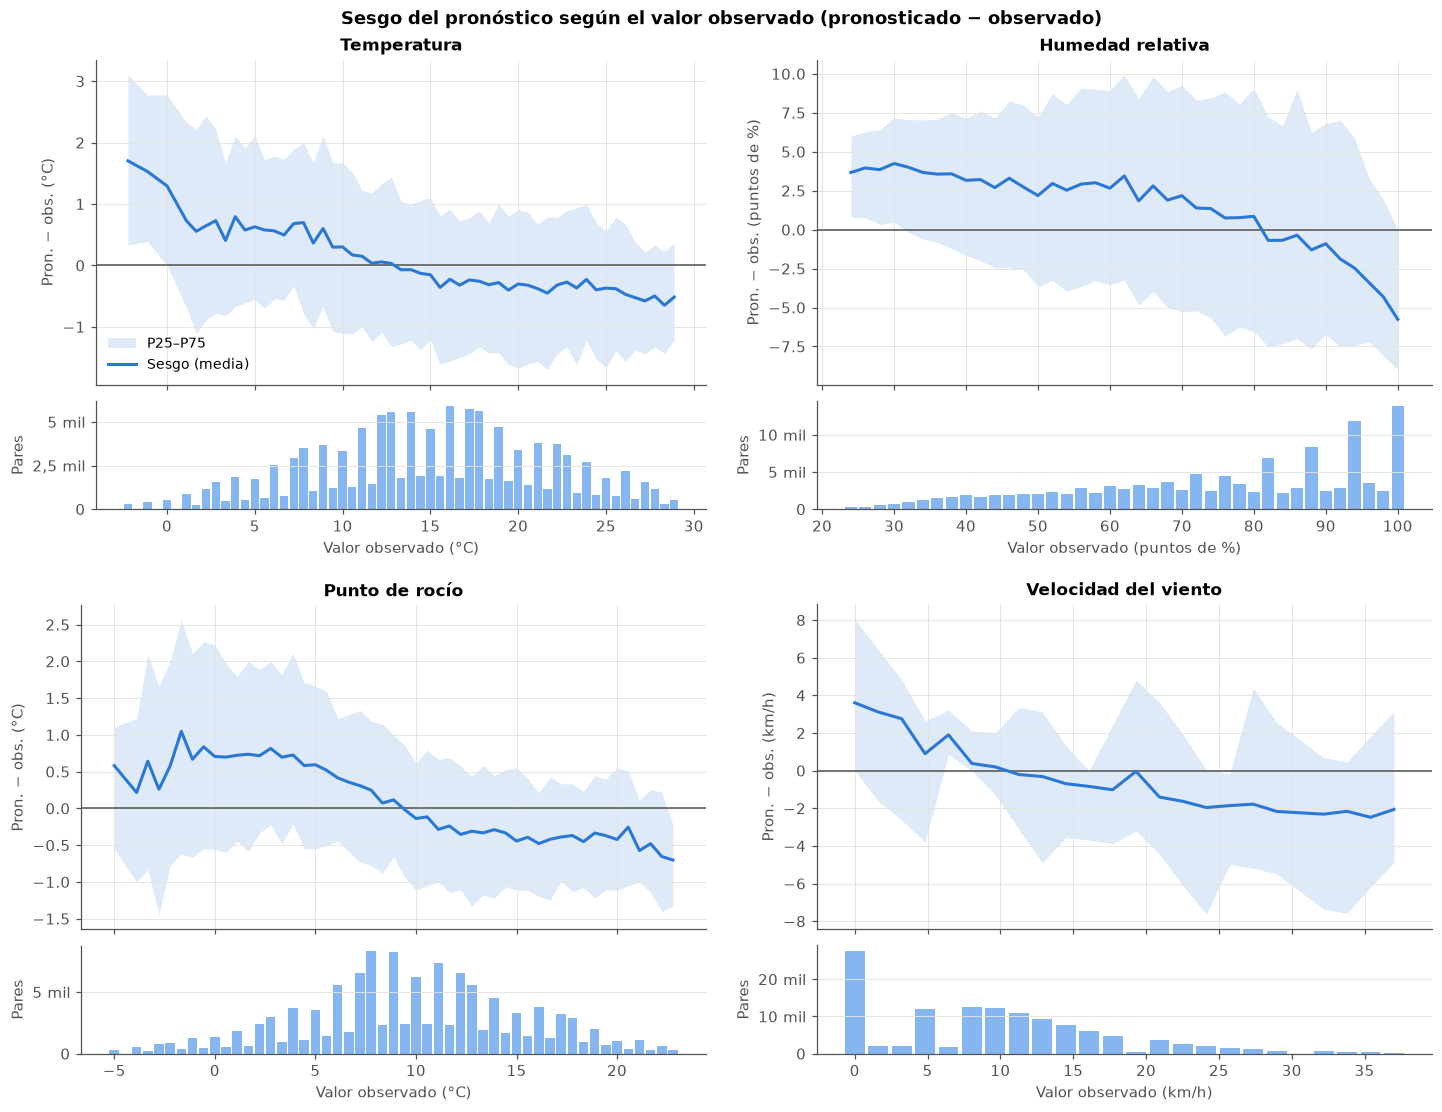

In [26]:
ANCHO_CLASE_OBS = {'Temperatura': 5 / 9, 'Humedad relativa': 2, 'Punto de rocío': 5 / 9, 'Velocidad del viento': 1.609344}


def sesgo_por_valor(datos, error, obs, ancho, n_min=200):
    """Sesgo, P25–P75 y n del error por clase del valor observado (clases centradas en múltiplos del ancho)."""
    d = datos[[obs, error]].dropna()
    g = d.groupby((d[obs] / ancho).round() * ancho)[error]
    tabla = g.agg(n='count', sesgo='mean').join(g.quantile([0.25, 0.75]).unstack())
    return tabla[tabla['n'] >= n_min]


fig = plt.figure(figsize=(13, 10), constrained_layout=True)
for sf, (nombre, unidad, _, obs, _) in zip(fig.subfigures(2, 2, wspace=0.03, hspace=0.03).flat, ERRORES):
    ax, ax_n = sf.subplots(2, 1, sharex=True, height_ratios=[3, 1])
    ancho = ANCHO_CLASE_OBS[nombre]
    t = sesgo_por_valor(mp, f'error_{nombre}', obs, ancho)
    ax.axhline(0, color=GRIS_TEXTO, lw=1)
    ax.fill_between(t.index, t[0.25], t[0.75], color=AZUL, alpha=0.15, linewidth=0, label='P25–P75')
    ax.plot(t.index, t['sesgo'], color=AZUL, lw=2, label='Sesgo (media)')
    ax.set(title=nombre, ylabel=f'Pron. − obs. ({unidad})')
    ax_n.bar(t.index, t['n'], width=ancho * 0.85, color='#86b6ef', linewidth=0)
    ax_n.set(xlabel=f'Valor observado ({unidad})', ylabel='Pares')
    ax_n.yaxis.set_major_formatter(lambda v, _: f'{v / 1000:g} mil'.replace('.', ',') if v else '0')
    ax_n.grid(axis='x', visible=False)
    if nombre == ERRORES[0][0]:
        ax.legend(frameon=False, loc='lower left', fontsize=9)
fig.suptitle('Sesgo del pronóstico según el valor observado (pronosticado − observado)', fontweight='bold')
figuras['10_sesgo_segun_observado'] = fig
plt.show()

Sesgo en las colas y en el centro de la distribución observada de cada variable (P10 y P90 del valor observado).
En el viento, P10 = 0 porque las calmas superan el 10 % de las observaciones, así que la primera columna corresponde a las calmas.

In [27]:
filas = {}
for nombre, _, _, obs, _ in ERRORES:
    d = mp[[obs, f'error_{nombre}']].dropna()
    p10, p90 = d[obs].quantile([0.1, 0.9])
    rango = pd.cut(d[obs], [-np.inf, p10, p90, np.inf], labels=['≤ P10', 'P10–P90', '> P90'])
    sesgo = d.groupby(rango, observed=False)[f'error_{nombre}'].mean()
    filas[nombre] = {'P10 obs.': p10, 'P90 obs.': p90, **{f'Sesgo obs. {r}': s for r, s in sesgo.items()}}
tabla_error_obs = pd.DataFrame(filas).T
tabla_error_obs.round(2)

,P10 obs.,P90 obs.,Sesgo obs. ≤ P10,Sesgo obs. P10–P90,Sesgo obs. > P90
Temperatura,6.00,24.00,0.80,-0.05,-0.50
Humedad relativa,44.16,100.00,3.50,-0.46,NaN
Punto de rocío,2.60,17.00,0.67,0.02,-0.42
Velocidad del viento,0.00,20.52,3.60,0.09,-1.95


La humedad relativa tiene `NaN` en "> P90": acá el P90 es 100 % (en TP2 era 93,97 %), así que no queda ningún par estrictamente por encima -tiene sentido, es una variable acotada arriba y esta muestra es más húmeda.

### Error según la elevación de la estación

La elevación es un atributo de la estación, así que se compara con el error **por estación**: cada punto es una estación con al
menos 100 pares de esa variable, con su sesgo (media de pronosticado − observado) y su MAE. El eje x está en escala logarítmica.

A diferencia de TP2 (estaciones concentradas en el área de Houston, con mediana de elevación bajo 40 m y ninguna por encima de
900 m), acá la muestra está mucho más repartida geográficamente -como ya se vio en la sección 7-: la elevación va de 0 a 1.701 m,
con mediana en 330 m, y la correlación elevación-latitud es bastante más débil (ρ de Spearman ≈ 0,31, frente a ≈ 0,8 en TP2) porque
las estaciones no se concentran en el sur bajo. Tampoco falta ninguna elevación (en TP2, ARDOT y RDOT no la informaban).

Esto separa mejor el efecto de la elevación del de la latitud, y el resultado cambia bastante respecto a TP2:

- En TP2 la elevación explicaba buena parte del error de temperatura, punto de rocío y humedad (ρ MAE–elev. entre 0,49 y 0,70).
  Acá esas correlaciones son casi nulas (entre −0,14 y 0,03): más alto no significa más error en estas tres variables.
- El viento es la excepción, y el patrón se invierte: en TP2 su correlación con la elevación era débil y dependía de APRSWXNET
  (ρ MAE–elev. pasaba de 0,23 a −0,21 al sacar esa red). Acá es la más fuerte de las cuatro (ρ = 0,53) y **no depende de
  APRSWXNET** (0,52 sin esa red): el MAE del viento crece con la elevación en todas las redes por igual.

Como ahora la red con más estaciones es `OTHER-MTR` (no `CENTERPOINT`), se colorean `OTHER-MTR` y `APRSWXNET` -esta última porque
sigue siendo, como en la sección 7, la que peor ajusta el viento.

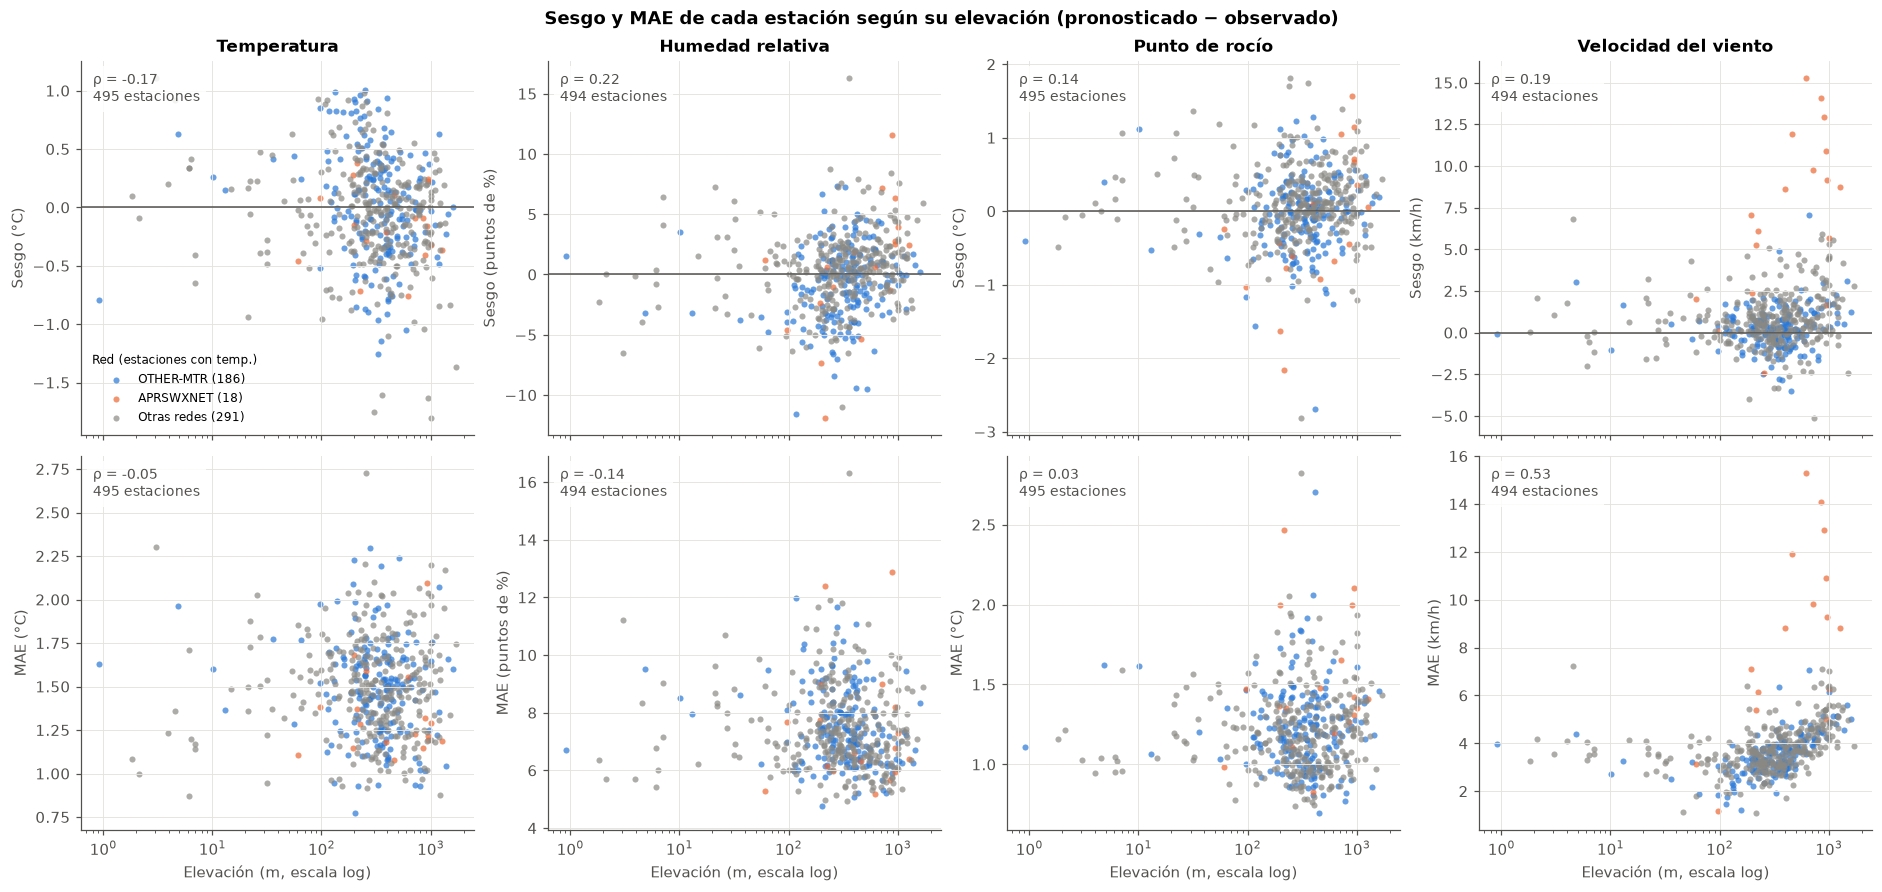

In [28]:
N_MIN_ESTACION = 100
COLORES_RED = {'OTHER-MTR': AZUL, 'APRSWXNET': NARANJA, 'Otras redes': '#8a8984'}

atributos_estacion = estaciones.set_index('station_id')[['elevation', 'latitud', 'red']]
filas = []
for nombre, *_ in ERRORES:
    g = mp.groupby('station_id')[f'error_{nombre}']
    por_estacion = (pd.DataFrame({'n': g.count(), 'Sesgo': g.mean(), 'MAE': g.apply(lambda e: e.abs().mean())})
                    .query('n >= @N_MIN_ESTACION').join(atributos_estacion).dropna(subset=['elevation']))
    filas.append(por_estacion.assign(variable=nombre))
error_estacion = pd.concat(filas).rename_axis('station_id').reset_index()
error_estacion['grupo_red'] = error_estacion['red'].where(error_estacion['red'].isin(COLORES_RED), 'Otras redes')

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, constrained_layout=True)
for j, (nombre, unidad, *_) in enumerate(ERRORES):
    d = error_estacion[error_estacion['variable'] == nombre]
    for i, metrica in enumerate(['Sesgo', 'MAE']):
        ax = axes[i, j]
        if metrica == 'Sesgo':
            ax.axhline(0, color=GRIS_TEXTO, lw=1)
        for grupo, color in COLORES_RED.items():
            dg = d[d['grupo_red'] == grupo]
            ax.scatter(dg['elevation'], dg[metrica], s=16, color=color, alpha=0.7, linewidths=0,
                       label=f'{grupo} ({len(dg)})' if j == 0 else None)
        rho = d['elevation'].corr(d[metrica], method='spearman')
        ax.text(0.03, 0.97, f'ρ = {rho:.2f}\n{len(d)} estaciones', transform=ax.transAxes, va='top', fontsize=9,
                color=GRIS_TEXTO, bbox=dict(fc='white', ec='none', alpha=0.85))
        ax.set(xscale='log', ylabel=f'{metrica} ({unidad})')
        if i == 0:
            ax.set_title(nombre)
        else:
            ax.set_xlabel('Elevación (m, escala log)')
axes[0, 0].legend(frameon=False, loc='lower left', fontsize=8, title='Red (estaciones con temp.)', title_fontsize=8)
fig.suptitle('Sesgo y MAE de cada estación según su elevación (pronosticado − observado)', fontweight='bold')
figuras['11_error_vs_elevacion'] = fig
plt.show()

Correlación de Spearman entre el error de cada estación y su elevación, con todas las redes y sin APRSWXNET, y la misma correlación
con la latitud como referencia. Debajo, el sesgo y el MAE medios de las estaciones por franja de elevación.

In [29]:
def rho_estaciones(d):
    return pd.Series({
        'estaciones': len(d),
        'ρ sesgo–elev.': d['elevation'].corr(d['Sesgo'], method='spearman'),
        'ρ MAE–elev.': d['elevation'].corr(d['MAE'], method='spearman'),
        'ρ sesgo–lat.': d['latitud'].corr(d['Sesgo'], method='spearman'),
        'ρ MAE–lat.': d['latitud'].corr(d['MAE'], method='spearman'),
    })


filas = {}
for nombre, *_ in ERRORES:
    d = error_estacion[error_estacion['variable'] == nombre]
    filas[(nombre, 'Todas las redes')] = rho_estaciones(d)
    filas[(nombre, 'Sin APRSWXNET')] = rho_estaciones(d[d['red'] != 'APRSWXNET'])
tabla_error_elevacion = pd.DataFrame(filas).T
tabla_error_elevacion['estaciones'] = tabla_error_elevacion['estaciones'].astype(int)
display(tabla_error_elevacion.round(2))

CORTES_ELEV = [0, 50, 200, 400, np.inf]
ETIQUETAS_ELEV = ['< 50 m', '50–200 m', '200–400 m', '> 400 m']
error_estacion['franja_elev'] = pd.cut(error_estacion['elevation'], CORTES_ELEV, labels=ETIQUETAS_ELEV)
(error_estacion.groupby(['variable', 'franja_elev'], observed=True)
 .agg(estaciones=('Sesgo', 'size'), Sesgo=('Sesgo', 'mean'), MAE=('MAE', 'mean'))
 .unstack('franja_elev').reindex([nombre for nombre, *_ in ERRORES]).round(2))

estaciones  ρ sesgo–elev.  ρ MAE–elev.  \
Temperatura          Todas las redes         495          -0.17        -0.05   
                     Sin APRSWXNET           477          -0.17        -0.05   
Humedad relativa     Todas las redes         494           0.22        -0.14   
                     Sin APRSWXNET           476           0.19        -0.14   
Punto de rocío       Todas las redes         495           0.14         0.03   
                     Sin APRSWXNET           477           0.12         0.01   
Velocidad del viento Todas las redes         494           0.19         0.53   
                     Sin APRSWXNET           476           0.16         0.52   

                                      ρ sesgo–lat.  ρ MAE–lat.  
Temperatura          Todas las redes         -0.09        0.35  
                     Sin APRSWXNET           -0.09        0.35  
Humedad relativa     Todas las redes          0.13        0.24  
                     Sin APRSWXNET            0.14        0.23  
Punto de rocío       Todas las redes          0.14        0.28  
                     Sin APRSWXNET            0.14        0.28  
Velocidad del viento Todas las redes          0.02        0.10  
                     Sin APRSWXNET            0.02        0.09

estaciones                             Sesgo           \
franja_elev              < 50 m 50–200 m 200–400 m > 400 m < 50 m 50–200 m   
variable                                                                     
Temperatura                  28       83       193     186   0.08     0.08   
Humedad relativa             28       83       193     185   0.24    -0.84   
Punto de rocío               28       83       193     186   0.16    -0.04   
Velocidad del viento         28       83       192     186   0.68     0.60   

                                          MAE                             
franja_elev          200–400 m > 400 m < 50 m 50–200 m 200–400 m > 400 m  
variable                                                                  
Temperatura               0.04   -0.14   1.47     1.52      1.49    1.47  
Humedad relativa         -0.44    1.02   7.74     7.60      7.64    7.16  
Punto de rocío            0.02    0.11   1.21     1.23      1.21    1.23  
Velocidad del viento      0.38    1.44   3.54     3.15      3.44    4.55

## 9. Conclusiones

**Calidad de los datos**

- Los negativos guardados como texto afectan acá a 4 columnas, no 3 como en TP2: además de `obs_temp_c`, `obs_dewpoint_c` y
  `fcst_dewpoint_c`, también `fcst_temp_c` -esta muestra va de fines de octubre a principios de noviembre, más fría que el
  septiembre de TP2, así que hay más negativos tanto en la observación como en el pronóstico.
- Casi no hubo que descartar valores imposibles: apenas 1 punto de rocío (frente a 44 temperaturas, 43 puntos de rocío y 6 vientos
  en TP2); el viento máximo observado fue de 59,4 km/h, muy por debajo del umbral de 120 km/h.
- A diferencia de TP2 (26 % de las filas excluidas por 129 estaciones sin sensores meteorológicos), acá no hizo falta excluir
  ninguna estación: la metadata ya viene filtrada desde `analisis_estaciones.ipynb` de este TP3. El dataset limpio tiene 498
  estaciones y 130.562 filas (vs. 345 estaciones y 217.297 filas en TP2).
- Sólo el 4,4 % de las filas no tiene ninguna observación (vs. 11,6 % en TP2 tras el filtro, 34,7 % antes). Cada variable
  observada tiene dato en 92,5–94,3 % de las filas (vs. 82–86 % en TP2). La excepción es la sensación térmica, con sólo 16,6 %
  (vs. 73 % en TP2): como sólo se informa con calor, en una muestra de estación fría aparece mucho menos.
- A diferencia de TP2 (ARDOT y RDOT sin elevación), ninguna estación de esta muestra tiene la elevación faltante.

**Observado vs. pronosticado (6 h)**

- Temperatura (r = 0,96, MAE = 1,48 °C) y punto de rocío (r = 0,96, MAE = 1,20 °C) se pronostican muy bien, con un error algo
  mayor que en TP2 (MAE 1,08 y 0,93 °C) pero la misma correlación.
- La humedad relativa acompaña igual de bien que en TP2 (r = 0,88 vs. 0,89; MAE 7,41 vs. 5,71 puntos).
- El viento sigue siendo la variable peor pronosticada, pero mucho menos que en TP2: r = 0,80 (vs. 0,52), sesgo −0,70 km/h
  (vs. −2,93), MAE 3,74 km/h (vs. 4,80). La mejora no es del pronóstico sino de la composición de la muestra: acá dominan redes
  profesionales (`OTHER-MTR`, `ASOS-HFM`, r ≈ 0,81–0,82) en vez de `CENTERPOINT` (r = 0,58 en TP2, 52 % de las filas). La red de
  aficionados `APRSWXNET` sigue siendo la peor en ambos TPs, con números casi idénticos: r = 0,43 (vs. 0,35), MAE = 7,81
  (vs. 7,77), ≈ 47 % de calmas observadas en los dos casos.

**Relaciones entre variables**

- Temperatura y HR: relación negativa (r = −0,55, ρ = −0,52), algo más débil que en TP2 (ρ = −0,71).
- Punto de rocío vs. temperatura: acá Pearson (0,69) y Spearman (0,67) son parecidos, a diferencia de TP2, donde Pearson (0,63)
  superaba bastante a Spearman (0,34) porque la relación se aplanaba en los extremos. En esta muestra el punto de rocío acompaña
  a la temperatura de forma más lineal en todo el rango.
- Sensación térmica vs. temperatura: coinciden casi del todo (r = 0,96, ρ = 0,97, igual que en TP2), aunque con muchos menos
  pares (21.714) por la escasez de calor en esta muestra.
- Humedad relativa vs. viento: relación negativa débil (r = −0,16, ρ = −0,17), más débil que en TP2 (ρ = −0,43).

**Error del pronóstico de temperatura**

- El patrón horario es más marcado y está corrido respecto a TP2: acá el pronóstico sobreestima más a media mañana
  (sesgo −1,61 °C a las 9 h) y subestima a la tarde-noche (sesgo +1,68 °C a las 18 h); en TP2 el signo era el opuesto y mucho
  más chico (+0,5 °C a las 9 h, −0,5 °C entre 13–19 h).
- La relación con la probabilidad de precipitación es mucho más suave que en TP2: el sesgo se mueve entre −0,27 °C (61–100 % de
  probabilidad) y +0,20 °C (11–20 %), lejos del −0,96 °C que tenía TP2 en el rango 41–60 %.

**Viento**

- Predominan los vientos del sur y sureste (52,6 % de las observaciones sin calma entre S y SE), coherente con el flujo desde
  el Golfo de México, igual que en TP2.
- A diferencia de TP2 (70 % de las observaciones concentradas en la franja del Golfo por la concentración de estaciones en
  Houston), acá la muestra está mucho más repartida geográficamente (sólo 12 % viene de esa franja), así que no hizo falta un
  recuadro ampliado en el mapa.
- La constancia del viento (qué tan fija es su dirección) baja de 0,67 en el Golfo a 0,32 en la franja norte (43–50°), un
  patrón parecido al de TP2 (0,48 a 0,24–0,30), pero el sesgo por franja no es monótono como en TP2: va de −0,52 km/h en el
  Golfo a −1,03 en 37–43° y vuelve a −0,57 en el norte, en vez de crecer sistemáticamente hacia el norte como en TP2
  (−2,6 a −3,9/−4,8 km/h).

**Error de pronóstico por variable (pronosticado − observado)**

- Temperatura (sesgo 0,00 °C, MAE 1,48, RMSE 1,88) y punto de rocío (sesgo 0,04 °C, MAE 1,20, RMSE 1,58) no tienen sesgo
  global, igual que en TP2, aunque con un error algo mayor.
- La humedad relativa tampoco tiene sesgo (−0,06 puntos) pero su error típico es alto (MAE 7,41, RMSE 9,80), similar a TP2.
- El viento es la única variable con sesgo claro, bastante menor que en TP2: +0,70 km/h (vs. +2,93), MAE 3,74 (vs. 4,80).
- Según el valor observado, las cuatro variables repiten el patrón de TP2 de no alcanzar los extremos (sobreestiman los valores
  bajos y subestiman los altos). La HR sigue siendo la más pronunciada (sesgo +3,50 en el P10 y cada vez más negativo hacia la
  saturación), con la diferencia de que en esta muestra el P90 de la HR es 100 %: no queda ningún par estrictamente por encima.

**Error según la elevación de la estación**

- El hallazgo más distinto de TP2: acá la elevación casi no se relaciona con el error de temperatura, HR ni punto de rocío
  (ρ MAE–elev. entre −0,14 y 0,03), mientras que en TP2 explicaba buena parte de esos errores (ρ entre 0,49 y 0,70). La
  diferencia principal es que esta muestra está mucho más repartida geográficamente, así que elevación y latitud están mucho
  menos confundidas entre sí (ρ elevación–latitud ≈ 0,31, vs. ≈ 0,8 en TP2).
- El viento es la excepción: acá tiene la correlación más fuerte de las cuatro (ρ MAE–elev. = 0,53) y, a diferencia de TP2
  (donde dependía de APRSWXNET y cambiaba de signo al sacarla), se mantiene casi igual sin esa red (0,52): el error de viento
  crece con la altura en todas las redes, no sólo en la de aficionados.

## 10. Exportación de los gráficos

In [30]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_obs_pron.to_csv(OUT + 'tabla_observado_vs_pronosticado.csv')
tabla_viento_franja.to_csv(OUT + 'tabla_viento_por_franja.csv')
tabla_error.to_csv(OUT + 'tabla_error_pronostico.csv')
tabla_error_hora.to_csv(OUT + 'tabla_error_por_hora.csv')
tabla_error_obs.to_csv(OUT + 'tabla_sesgo_segun_observado.csv')
tabla_error_elevacion.to_csv(OUT + 'tabla_error_vs_elevacion.csv')
print(f'Guardados {len(figuras)} gráficos y 6 tablas en {OUT}')

Guardados 11 gráficos y 6 tablas en ../data/out/bivariadas/
